# Rotating Machinery Predictive Maintenance Suite
**Author:** Harpreet Singh (GitHub: hskhalsa1990) | **Data:** 100 % synthetic | **License:** MIT

Fault detection and remaining useful life (RUL) for motors, pumps, gearboxes and bearings from vibration signals.

**How to read this notebook:** each section says which Kaggle Learn topic it practises. Every chart is also saved as a PNG in the current folder.

**Honesty box**
- All signals, readings and texts are *simulated*. Results show that the pipeline works on simulated data; they do NOT prove performance on real machines.
- PyTorch 1D-CNN / LSTM code exists (`deep_torch.py`) but was NOT executed by the author. The neural networks that were executed here are scikit-learn MLPs.
- ISO 10816 limits are illustrative values; check the current standard (ISO 20816).

In [ ]:
import sqlite3
import time
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

import cleaning as cl
import datagen as dg
import db
import features as ft
import iso10816 as iso
import maintenance as mt
import rul
import textlogs
from plotting import SAVED, save

try:
    display
except NameError:
    display = print
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
SEED = 42
np.random.seed(SEED)
T_START = time.time()
print("setup ok")

setup ok


## 1. Python and Pandas: physics-based synthetic data
`datagen.py` simulates acceleration signals (12 kHz, 4096 samples):
- **imbalance** -> large 1x shaft component (grows with speed squared)
- **misalignment** -> strong 2x and 3x
- **bearing outer / inner race** -> periodic impacts at BPFO / BPFI that ring a structural resonance
- **gear tooth** -> gear-mesh tone with shaft-speed sidebands
- every machine has its own sensor gain, resonance frequency and noise level; speed and load vary per signal.

In [ ]:
signals, meta = dg.generate_dataset(n_machines=30, per_class=8, seed=SEED)
print("signals:", signals.shape, "| classes:", dg.FAULTS)
g = dg.BearingGeometry()
print("defect frequencies at 25 Hz shaft speed [Hz]:", {k: round(getattr(g, k)(25.0), 1) for k in ["bpfo", "bpfi", "bsf", "ftf"]})
meta.groupby("fault")[["severity", "speed_hz", "load"]].mean().round(2)

signals: (1440, 4096) | classes: ['healthy', 'imbalance', 'misalignment', 'bearing_outer', 'bearing_inner', 'gear_tooth']
defect frequencies at 25 Hz shaft speed [Hz]: {'bpfo': np.float64(89.6), 'bpfi': np.float64(135.4), 'bsf': np.float64(58.9), 'ftf': np.float64(10.0)}


               severity  speed_hz  load
fault                                  
bearing_inner      0.57     25.24  0.66
bearing_outer      0.55     24.97  0.64
gear_tooth         0.56     24.81  0.64
healthy            0.00     24.72  0.65
imbalance          0.56     25.14  0.62
misalignment       0.58     24.94  0.64

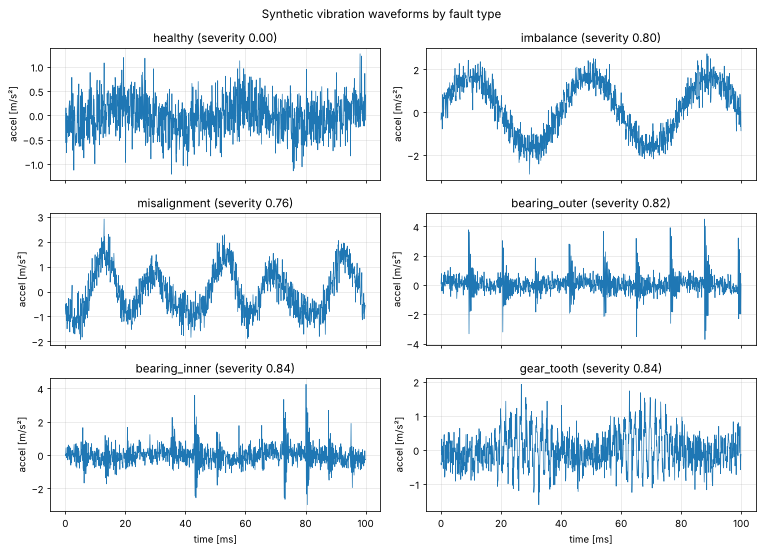

In [ ]:
def pick(fault, sev=0.8, speed=25.0):
    d = meta[meta.fault == fault]
    score = (d.severity - sev).abs() / 0.5 + (d.speed_hz - speed).abs() / 5
    return int(d.loc[score.idxmin(), "sample_id"])


idx = {f: pick(f, 0.0 if f == "healthy" else 0.8) for f in dg.FAULTS}
fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
tms = np.arange(1200) / dg.FS * 1000
for ax, f in zip(axes.ravel(), dg.FAULTS):
    ax.plot(tms, signals[idx[f], :1200], lw=0.7)
    ax.set_title(f"{f} (severity {meta.severity[idx[f]]:.2f})")
    ax.set_ylabel("accel [m/s²]")
axes[-1, 0].set_xlabel("time [ms]")
axes[-1, 1].set_xlabel("time [ms]")
fig.suptitle("Synthetic vibration waveforms by fault type")
fig.tight_layout()
save(fig, "01_signals_by_fault.png")
plt.show()

## 2. Data Visualization: spectrum, envelope spectrum, 3D waterfall
Bearing faults hide in the raw spectrum but show up in the **envelope spectrum** (band-pass around the resonance, then Hilbert envelope).

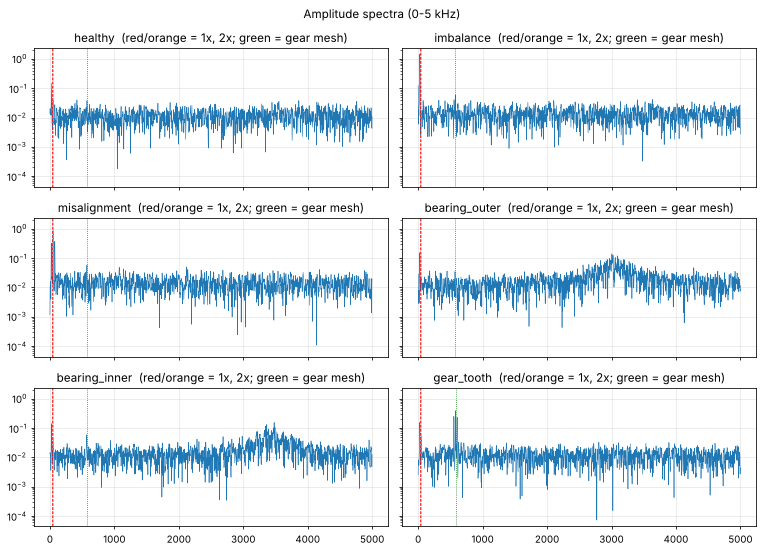

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, f in zip(axes.ravel(), dg.FAULTS):
    i = idx[f]
    fr = meta.speed_hz[i]
    fq, a = ft.amplitude_spectrum(signals[i])
    m = fq <= 5000
    ax.semilogy(fq[m], a[m] + 1e-6, lw=0.6)
    for k, c in ((1, "r"), (2, "orange")):
        ax.axvline(k * fr, color=c, ls="--", lw=0.8)
    ax.axvline(dg.N_TEETH * fr, color="g", ls=":", lw=0.8)
    ax.set_title(f"{f}  (red/orange = 1x, 2x; green = gear mesh)")
fig.suptitle("Amplitude spectra (0-5 kHz)")
fig.tight_layout()
save(fig, "02_spectra_by_fault.png")
plt.show()

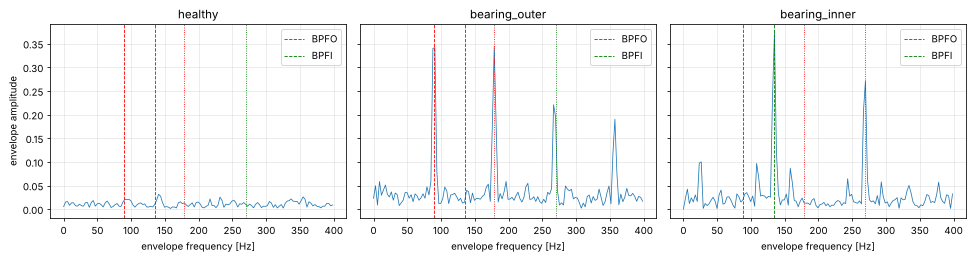

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, f in zip(axes, ["healthy", "bearing_outer", "bearing_inner"]):
    i = idx[f]
    fr = meta.speed_hz[i]
    fe, E = ft.envelope_spectrum(signals[i])
    m = fe <= 400
    ax.plot(fe[m], E[m], lw=0.8)
    for f0, c, lab in ((g.bpfo(fr), "r", "BPFO"), (g.bpfi(fr), "g", "BPFI")):
        ax.axvline(f0, color=c, ls="--", lw=0.9, label=lab)
        ax.axvline(2 * f0, color=c, ls=":", lw=0.9)
    ax.set_title(f)
    ax.set_xlabel("envelope frequency [Hz]")
    ax.legend()
axes[0].set_ylabel("envelope amplitude")
fig.tight_layout()
save(fig, "03_envelope_spectrum.png")
plt.show()

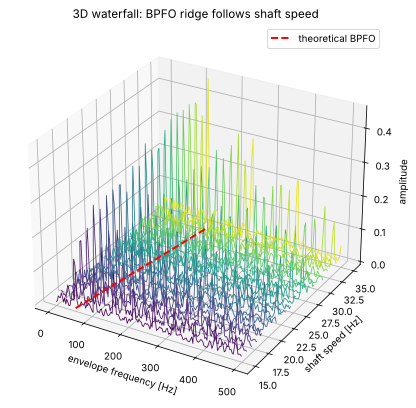

In [ ]:
# 3D waterfall: envelope spectra of an outer-race fault while shaft speed ramps 15 -> 35 Hz.
rng = np.random.default_rng(5)
mp = dg.MachineParams(0, 1.0, 3000.0, 0.3)
speeds = np.linspace(15, 35, 22)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for k, sp in enumerate(speeds):
    x = dg.generate_signal("bearing_outer", 0.8, sp, 0.6, rng, mp=mp)
    fe, E = ft.envelope_spectrum(x)
    m = fe <= 500
    ax.plot(fe[m], np.full(m.sum(), sp), E[m], lw=0.8, color=plt.cm.viridis(k / len(speeds)))
ax.plot([g.bpfo(s) for s in speeds], speeds, np.zeros(len(speeds)), "r--", lw=2, label="theoretical BPFO")
ax.set_xlabel("envelope frequency [Hz]")
ax.set_ylabel("shaft speed [Hz]")
ax.set_zlabel("amplitude")
ax.set_title("3D waterfall: BPFO ridge follows shaft speed")
ax.legend()
ax.view_init(elev=28, azim=-60)
save(fig, "04_waterfall_3d.png")
plt.show()

## 3. SQL and Advanced SQL: SQLite database with window functions
Six fictional plants in Punjab, 24 machines, 120 days of daily readings and maintenance logs.
Readings here are *summary-level* values from a simple trend model (not from the waveform generator).
Queries use `JOIN`, `CTE`, `LAG`, rolling `AVG() OVER`, `RANK`, `NTILE`, and cumulative `SUM() OVER`.

In [ ]:
conn = db.create_demo_database("pdm_demo.db")
print("SQLite version:", sqlite3.sqlite_version)
for t in ["plants", "machines", "readings", "maintenance_logs"]:
    print(f"{t:18s} rows:", pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", conn).n[0])
plant_summary = db.run_query(conn, "plant_summary")
display(plant_summary)
roll = db.run_query(conn, "rolling_trend")
rank = db.run_query(conn, "latest_rank")
display(rank.head(8))
display(db.run_query(conn, "first_zone_c"))
cum = db.run_query(conn, "cumulative_cost")
cum.tail(5)

SQLite version: 3.45.1
plants             rows: 6
machines           rows: 24
readings           rows: 2880
maintenance_logs   rows: 36
  plant_name  n_machines  avg_vel  max_vel
0  Plant-MOH           4     1.55     3.58
1  Plant-JAL           4     1.53     4.53
2  Plant-PTA           4     1.37     3.57
3  Plant-LDH           4     1.33     4.26
4  Plant-BTI           4     1.07     1.42
5  Plant-ASR           4     0.97     2.10
   plant_id  machine_id machine_type  vel_rms  rank_in_plant  risk_quartile
0         1           4          fan     4.26              1              4
1         1           2         pump     3.11              2              3
2         1           1        motor     1.23              3              2
3         1           3      gearbox     0.75              4              1
4         2           5   compressor     4.53              1              4
5         2           7         pump     3.51              2              4
6         2           6        

   plant_name    log_date      cost_inr   cum_cost_inr
31  Plant-MOH  2026-01-21   2000.000000    6000.000000
32  Plant-MOH  2026-01-25   2000.000000    8000.000000
33  Plant-MOH  2026-02-25  30735.775872   38735.775872
34  Plant-MOH  2026-03-22  42589.378374   81325.154246
35  Plant-MOH  2026-03-25  38812.418968  120137.573214

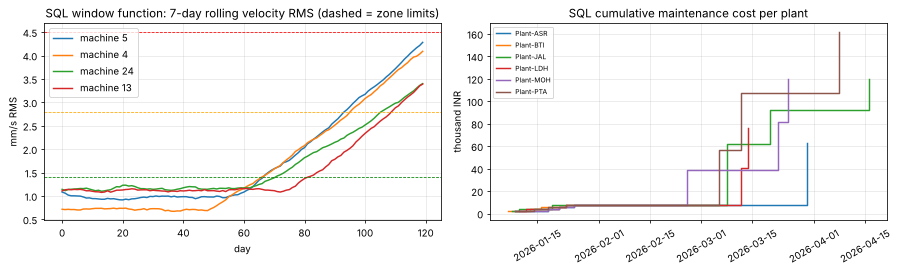

In [ ]:
top = roll.groupby("machine_id").vel_rms.max().nlargest(4).index
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mid in top:
    d = roll[roll.machine_id == mid]
    axes[0].plot(d.day, d.vel_7d_avg, label=f"machine {mid}")
for lim, c in zip(iso.THRESHOLDS["medium_rigid"], ("g", "orange", "r")):
    axes[0].axhline(lim, color=c, ls="--", lw=0.8)
axes[0].set_title("SQL window function: 7-day rolling velocity RMS (dashed = zone limits)")
axes[0].set_xlabel("day")
axes[0].set_ylabel("mm/s RMS")
axes[0].legend()
for name, d in cum.groupby("plant_name"):
    axes[1].step(pd.to_datetime(d.log_date), d.cum_cost_inr / 1000, where="post", label=name)
axes[1].set_title("SQL cumulative maintenance cost per plant")
axes[1].set_ylabel("thousand INR")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=7)
fig.tight_layout()
save(fig, "05_sql_window_trends.png")
plt.show()

## 3b. Pandas deep dive: merge, pivot_table, resample, rolling
The same SQLite data again, now with pandas tools:
- `merge` (with `validate=`) to join readings, machines and plants; `merge_asof` to attach the latest reading to each maintenance log
- `pivot_table` for a plant x machine-type table
- `resample` to turn daily readings into weekly means per plant
- `rolling` to rebuild the SQL 7-day moving average in pandas and **check that both agree**

In [ ]:
readings = pd.read_sql("SELECT * FROM readings", conn, parse_dates=["read_date"])
machines = pd.read_sql("SELECT * FROM machines", conn)
plants_df = pd.read_sql("SELECT plant_id, plant_name, city FROM plants", conn)
logs = pd.read_sql("SELECT * FROM maintenance_logs", conn, parse_dates=["log_date"])

# merge: many readings -> one machine -> one plant (validate stops silent row duplication)
full = (readings.merge(machines, on="machine_id", how="left", validate="many_to_one")
                .merge(plants_df, on="plant_id", how="left", validate="many_to_one"))
print("rows before/after merge:", len(readings), len(full), "| missing plant after merge:", int(full.plant_name.isna().sum()))

# merge_asof: for every log, the most recent reading of the same machine on or before the log date
asof = pd.merge_asof(logs.sort_values("log_date"), readings.sort_values("read_date")[["machine_id", "read_date", "vel_rms"]],
                     left_on="log_date", right_on="read_date", by="machine_id", direction="backward")
print("logs with a reading found:", int(asof.vel_rms.notna().sum()), "of", len(asof))

# pivot_table: mean velocity RMS by city and machine type, with totals
pv = full.pivot_table(values="vel_rms", index="city", columns="machine_type", aggfunc="mean", margins=True, margins_name="ALL").round(2)
display(pv)

# resample: weekly mean per plant
weekly = full.set_index("read_date").groupby("plant_name").vel_rms.resample("W").mean().unstack(0)
print("weekly table shape (weeks x plants):", weekly.shape)

# rolling: 7-day mean/std per machine; min_periods=1 matches the SQL window (ROWS 6 PRECEDING)
full = full.sort_values(["machine_id", "day"]).reset_index(drop=True)
g = full.groupby("machine_id").vel_rms
full["roll_mean7"] = g.transform(lambda s: s.rolling(7, min_periods=1).mean())
full["roll_std7"] = g.transform(lambda s: s.rolling(7, min_periods=2).std())
cmp_ = full.merge(roll[["machine_id", "day", "vel_7d_avg"]], on=["machine_id", "day"], validate="one_to_one")
print("pandas rolling mean equals SQL window AVG:", bool(np.allclose(cmp_.roll_mean7, cmp_.vel_7d_avg)),
      "| max abs difference:", float((cmp_.roll_mean7 - cmp_.vel_7d_avg).abs().max()))

rows before/after merge: 2880 2880 | missing plant after merge: 0
logs with a reading found: 36 of 36
machine_type  compressor   fan  gearbox  motor  pump   ALL
city                                                      
Amritsar            1.20  0.71      NaN   0.89  1.08  0.97
Bathinda            0.89  1.23     1.29    NaN  0.86  1.07
Jalandhar           1.88   NaN     1.20   1.39  1.66  1.53
Ludhiana             NaN  1.74     0.72   1.23  1.61  1.33
Mohali               NaN  1.72     1.89   0.98  1.61  1.55
Patiala             1.63  0.90     1.58   1.37   NaN  1.37
ALL                 1.40  1.26     1.34   1.17  1.36  1.30
weekly table shape (weeks x plants): (18, 6)
pandas rolling mean equals SQL window AVG: True | max abs difference: 8.881784197001252e-16


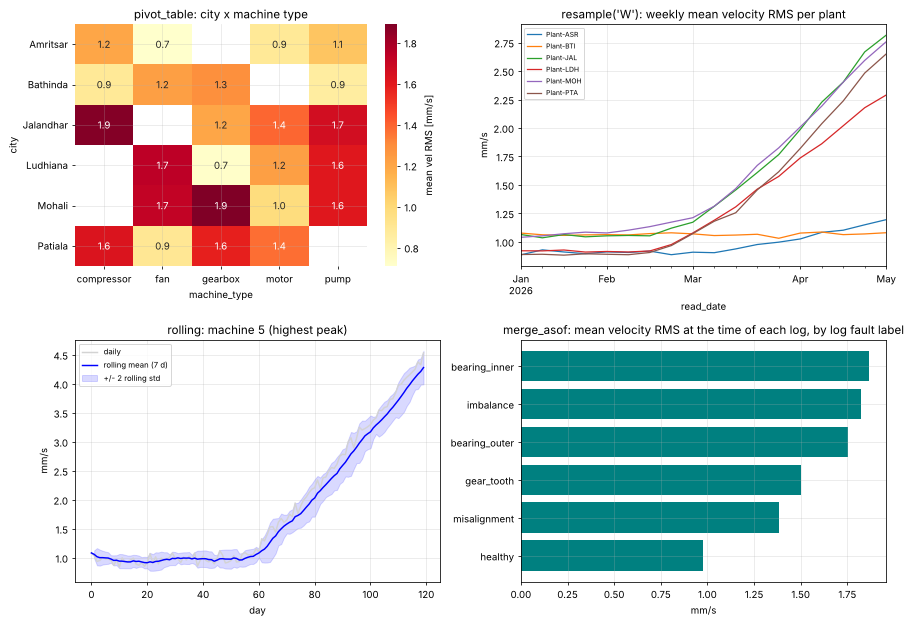

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.heatmap(pv.drop(index="ALL", columns="ALL"), annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0, 0], cbar_kws={"label": "mean vel RMS [mm/s]"})
axes[0, 0].set_title("pivot_table: city x machine type")
weekly.plot(ax=axes[0, 1], lw=1.3)
axes[0, 1].set_title("resample('W'): weekly mean velocity RMS per plant")
axes[0, 1].set_ylabel("mm/s")
axes[0, 1].legend(fontsize=7)
mm = full.groupby("machine_id").vel_rms.max().idxmax()
d = full[full.machine_id == mm]
axes[1, 0].plot(d.day, d.vel_rms, color="lightgray", label="daily")
axes[1, 0].plot(d.day, d.roll_mean7, "b", label="rolling mean (7 d)")
axes[1, 0].fill_between(d.day, d.roll_mean7 - 2 * d.roll_std7, d.roll_mean7 + 2 * d.roll_std7, color="blue", alpha=0.15, label="+/- 2 rolling std")
axes[1, 0].set_title(f"rolling: machine {mm} (highest peak)")
axes[1, 0].set_xlabel("day")
axes[1, 0].set_ylabel("mm/s")
axes[1, 0].legend(fontsize=8)
a2 = asof.groupby("fault_label").vel_rms.mean().sort_values()
axes[1, 1].barh(a2.index, a2.values, color="teal")
axes[1, 1].set_title("merge_asof: mean velocity RMS at the time of each log, by log fault label")
axes[1, 1].set_xlabel("mm/s")
fig.tight_layout()
save(fig, "33_pandas_merge_pivot_resample_rolling.png")
plt.show()

## 4. Data Cleaning: missing values, outliers, stuck sensors, duplicates
We inject typical sensor problems into the SQL readings, then clean them (duplicate removal, flat-line detection, Hampel outlier filter, short-gap interpolation) and compare with the known truth.

{'rows_in': 2909, 'duplicates_removed': 29, 'missing_before': 182, 'flatline_points': 48, 'outliers': 150, 'missing_after': 12}
MAE vs truth (ignoring NaN): messy = 0.112 mm/s | cleaned = 0.007 mm/s


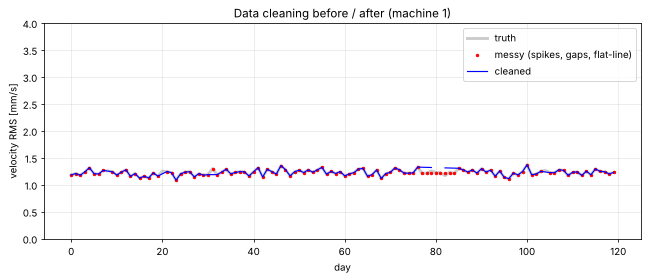

In [ ]:
raw = pd.read_sql("SELECT * FROM readings", conn)
messy = cl.make_messy(raw, seed=3)
clean, rep = cl.clean_readings(messy)
print(rep)
truth = raw.set_index(["machine_id", "day"])["vel_rms"]


def mae(d):
    j = d.drop_duplicates(["machine_id", "day"]).set_index(["machine_id", "day"])["vel_rms"]
    return float((j - truth.reindex(j.index)).abs().mean())


print(f"MAE vs truth (ignoring NaN): messy = {mae(messy):.3f} mm/s | cleaned = {mae(clean):.3f} mm/s")
mid = 1
m1 = messy[messy.machine_id == mid].drop_duplicates("day").sort_values("day")
c1 = clean[clean.machine_id == mid]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(raw[raw.machine_id == mid].day, raw[raw.machine_id == mid].vel_rms, color="gray", lw=3, alpha=0.4, label="truth")
ax.plot(m1.day, m1.vel_rms, "r.", ms=5, label="messy (spikes, gaps, flat-line)")
ax.plot(c1.day, c1.vel_rms, "b-", lw=1.2, label="cleaned")
ax.set_ylim(0, max(4, c1.vel_rms.max() * 1.5))
ax.set_xlabel("day")
ax.set_ylabel("velocity RMS [mm/s]")
ax.set_title("Data cleaning before / after (machine 1)")
ax.legend()
save(fig, "06_cleaning_before_after.png")
plt.show()

## 5. Feature Engineering
Time-domain (RMS, crest factor, kurtosis, ...), velocity RMS (ISO quantity), harmonics 1x/2x/3x, gear-mesh sidebands and **envelope SNR at BPFO/BPFI**. These physics-based features use the shaft speed (assumed to come from a tachometer).

In [ ]:
t0 = time.time()
feats = ft.features_dataframe(signals, meta.speed_hz)
print(f"{feats.shape[1]} features x {len(feats)} signals in {time.time() - t0:.1f}s")
feats.describe().T[["mean", "std", "min", "max"]].round(3)

20 features x 1440 signals in 3.9s


                    mean      std      min       max
rms                0.546    0.224    0.250     1.892
peak               2.251    1.112    0.858     8.454
crest              4.236    1.494    1.856     9.093
kurtosis           3.930    2.529    1.582    17.229
skewness           0.094    0.205   -0.497     0.854
shape_factor       1.272    0.090    1.117     1.698
impulse_factor     5.514    2.416    2.078    14.276
vel_rms            1.626    1.649    0.496    10.114
a1x                0.314    0.363    0.098     2.613
a2x                0.119    0.222    0.004     1.161
a3x                0.058    0.097    0.002     0.518
a2x_over_1x        0.481    0.754    0.008     3.322
a3x_over_1x        0.243    0.327    0.003     1.401
mesh_amp           0.076    0.074    0.019     0.436
sideband_amp       0.032    0.050    0.004     0.318
sideband_ratio     0.370    0.157    0.097     1.207
env_snr_bpfo       2.979    3.702    0.590    20.142
env_snr_bpfi       3.542    3.750    0.672    

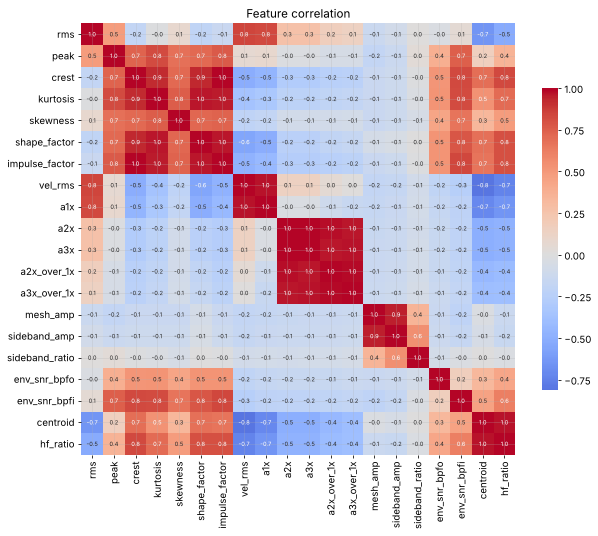

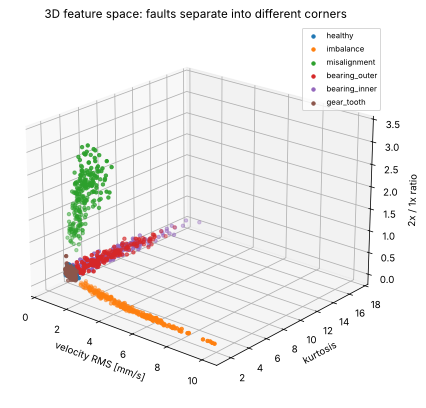

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(feats.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Feature correlation")
save(fig, "07_feature_correlation.png")
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for f in dg.FAULTS:
    m = (meta.fault == f).to_numpy()
    ax.scatter(feats.vel_rms[m], feats["kurtosis"][m], feats.a2x_over_1x[m], s=12, label=f)
ax.set_xlabel("velocity RMS [mm/s]")
ax.set_ylabel("kurtosis")
ax.set_zlabel("2x / 1x ratio")
ax.set_title("3D feature space: faults separate into different corners")
ax.legend(fontsize=8)
ax.view_init(elev=22, azim=-50)
save(fig, "08_features_3d_scatter.png")
plt.show()

## 6. ISO 10816-style zones and alarm logic
Zone A/B = fine, C = restricted (plan maintenance), D = damage possible. **Important lesson:** velocity RMS reacts to imbalance / misalignment but barely to early bearing or gear faults, which is why we also need kurtosis, envelope and other features.

zone             A    B   C    D
fault                           
bearing_inner  240    0   0    0
bearing_outer  240    0   0    0
gear_tooth     240    0   0    0
healthy        240    0   0    0
imbalance        0   50  68  122
misalignment    54  156  30    0


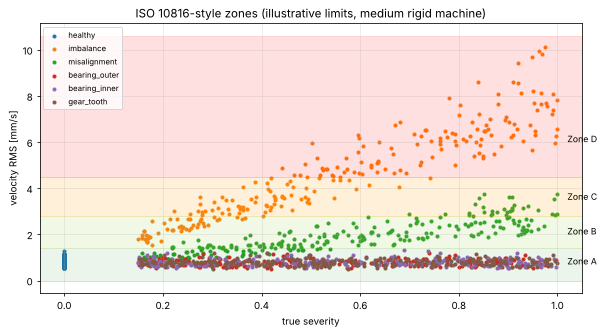

In [ ]:
meta["zone"] = feats.vel_rms.map(iso.zone)
display(pd.crosstab(meta.fault, meta.zone))
fig, ax = plt.subplots(figsize=(10, 5))
for f in dg.FAULTS:
    m = meta.fault == f
    ax.scatter(meta.severity[m], feats.vel_rms[m], s=10, label=f)
lims = iso.THRESHOLDS["medium_rigid"]
ax.axhspan(0, lims[0], color="green", alpha=0.08)
ax.axhspan(lims[0], lims[1], color="yellowgreen", alpha=0.12)
ax.axhspan(lims[1], lims[2], color="orange", alpha=0.15)
ax.axhspan(lims[2], feats.vel_rms.max() * 1.05, color="red", alpha=0.12)
for lab, y in zip("ABCD", (0.7, 2.0, 3.5, 6.0)):
    ax.text(1.02, y, f"Zone {lab}", fontsize=9)
ax.set_xlabel("true severity")
ax.set_ylabel("velocity RMS [mm/s]")
ax.set_title("ISO 10816-style zones (illustrative limits, medium rigid machine)")
ax.legend(fontsize=8)
save(fig, "09_iso_zones.png")
plt.show()

## 7. Intro and Intermediate Machine Learning
Topics: under/over-fitting (tree depth), pipelines, cross-validation. **Validation is grouped by machine** (`GroupKFold`), so a model is always tested on machines it has never seen. That is harder (and more honest) than a random split, because every machine has its own sensor gain and resonance.

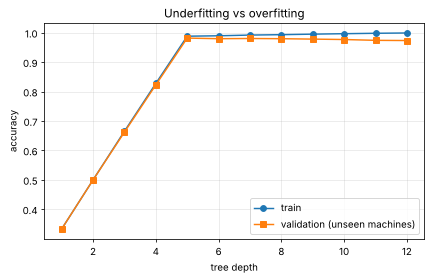

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

X, y, groups = feats[ft.FEATURE_COLS], meta.label, meta.machine_id
cv = GroupKFold(n_splits=5)
depths = range(1, 13)
tr_s, va_s = [], []
for d in depths:
    r = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), X, y, groups=groups, cv=cv, return_train_score=True)
    tr_s.append(r["train_score"].mean())
    va_s.append(r["test_score"].mean())
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, tr_s, "o-", label="train")
ax.plot(depths, va_s, "s-", label="validation (unseen machines)")
ax.set_xlabel("tree depth")
ax.set_ylabel("accuracy")
ax.set_title("Underfitting vs overfitting")
ax.legend()
save(fig, "10_tree_depth_curve.png")
plt.show()

In [ ]:
models = {
    "Logistic regression": Pipeline([("imp", SimpleImputer()), ("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=3000))]),
    "Random forest": Pipeline([("imp", SimpleImputer()), ("clf", RandomForestClassifier(300, random_state=SEED))]),
    "Hist. gradient boosting": Pipeline([("imp", SimpleImputer()), ("clf", HistGradientBoostingClassifier(max_iter=100, random_state=SEED))]),
}
rows = []
for name, mdl in models.items():
    t0 = time.time()
    r = cross_validate(mdl, X, y, groups=groups, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append(dict(model=name, input="20 engineered features", accuracy=r["test_accuracy"].mean(), acc_std=r["test_accuracy"].std(),
                     macro_f1=r["test_f1_macro"].mean(), evaluation="5-fold GroupKFold (by machine)", status="executed"))
    print(f"{name:25s} acc {rows[-1]['accuracy']:.3f} +/- {rows[-1]['acc_std']:.3f}  F1 {rows[-1]['macro_f1']:.3f}  ({time.time() - t0:.0f}s)")

Logistic regression       acc 0.980 +/- 0.008  F1 0.980  (0s)
Random forest             acc 0.984 +/- 0.011  F1 0.984  (3s)
Hist. gradient boosting   acc 0.983 +/- 0.014  F1 0.983  (3s)


               precision    recall  f1-score   support

      healthy      0.925     0.983     0.954       240
    imbalance      1.000     1.000     1.000       240
 misalignment      1.000     1.000     1.000       240
bearing_outer      0.996     0.967     0.981       240
bearing_inner      0.991     0.967     0.979       240
   gear_tooth      0.996     0.988     0.992       240

     accuracy                          0.984      1440
    macro avg      0.985     0.984     0.984      1440
 weighted avg      0.985     0.984     0.984      1440



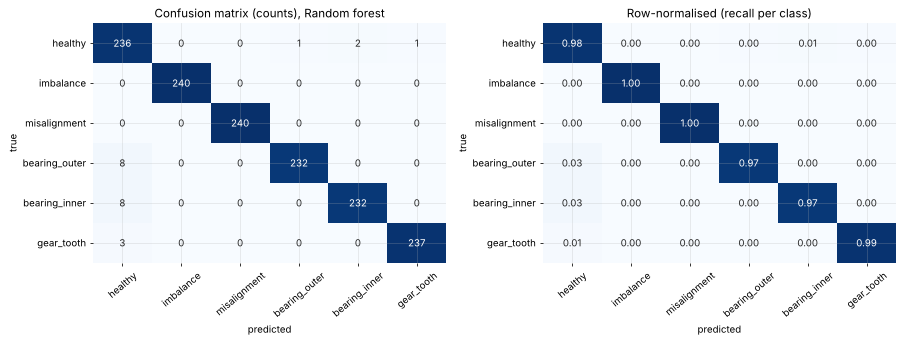

In [ ]:
rf = models["Random forest"]
pred_rf = cross_val_predict(rf, X, y, groups=groups, cv=cv)
cm = confusion_matrix(y, pred_rf)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dg.FAULTS, yticklabels=dg.FAULTS, ax=axes[0], cbar=False)
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=dg.FAULTS, yticklabels=dg.FAULTS, ax=axes[1], cbar=False)
axes[0].set_title("Confusion matrix (counts), Random forest")
axes[1].set_title("Row-normalised (recall per class)")
for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
save(fig, "11_confusion_matrix_rf.png")
plt.show()
print(classification_report(y, pred_rf, target_names=dg.FAULTS, digits=3))

overall missed-fault rate (fault predicted as healthy): 1.6 %


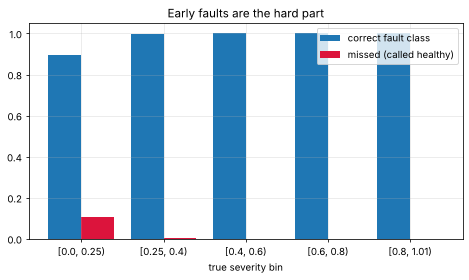

In [ ]:
# Honest breakdown: how does accuracy depend on fault severity? How many real faults are called "healthy"?
bins = [0, 0.25, 0.4, 0.6, 0.8, 1.01]
fm = meta.fault != "healthy"
sev_bin = pd.cut(meta.severity[fm], bins, right=False)
pred_s = pd.Series(pred_rf, index=meta.index)
acc_bin = (pred_s[fm] == y[fm]).groupby(sev_bin).mean()
miss_bin = (pred_s[fm] == 0).groupby(sev_bin).mean()
fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(acc_bin))
ax.bar(xx - 0.2, acc_bin.values, 0.4, label="correct fault class")
ax.bar(xx + 0.2, miss_bin.values, 0.4, label="missed (called healthy)", color="crimson")
ax.set_xticks(xx)
ax.set_xticklabels([str(i) for i in acc_bin.index])
ax.set_xlabel("true severity bin")
ax.set_title("Early faults are the hard part")
ax.legend()
save(fig, "12_accuracy_by_severity.png")
plt.show()
print("overall missed-fault rate (fault predicted as healthy): %.1f %%" % (100 * (pred_s[fm] == 0).mean()))

{0: np.float64(0.969), 0.2: np.float64(0.941), 0.4: np.float64(0.924), 0.8: np.float64(0.83), 1.2: np.float64(0.653)}


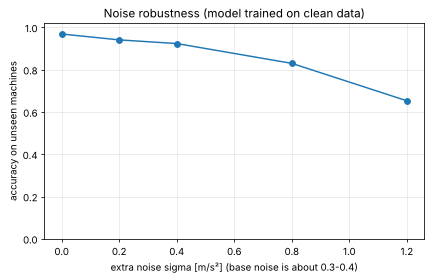

In [ ]:
# Robustness: train on clean data, test on held-out machines with EXTRA sensor noise.
tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(X, y, groups))
rf_fit = RandomForestClassifier(300, random_state=SEED).fit(X.iloc[tr], y.iloc[tr])
rng = np.random.default_rng(9)
levels = [0, 0.2, 0.4, 0.8, 1.2]
accs = []
for s in levels:
    sig = signals[te] + (rng.normal(0, s, signals[te].shape) if s > 0 else 0)
    F = ft.features_dataframe(sig, meta.speed_hz.iloc[te])
    accs.append(accuracy_score(y.iloc[te], rf_fit.predict(F)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(levels, accs, "o-")
ax.set_xlabel("extra noise sigma [m/s²] (base noise is about 0.3-0.4)")
ax.set_ylabel("accuracy on unseen machines")
ax.set_ylim(0, 1.02)
ax.set_title("Noise robustness (model trained on clean data)")
save(fig, "13_noise_robustness.png")
plt.show()
print(dict(zip(levels, np.round(accs, 3))))

## 8. Machine Learning Explainability
Permutation importance on held-out machines (how much accuracy drops when one feature is shuffled). SHAP is not installed in the build environment; an optional SHAP cell is included and skipped if the package is missing.

env_snr_bpfo    0.185
mesh_amp        0.156
env_snr_bpfi    0.062
hf_ratio        0.004
shape_factor    0.003
a3x             0.003
dtype: float64
shap not installed -> optional SHAP step skipped (not verified)


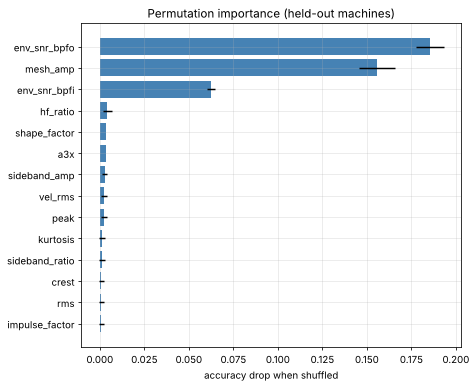

In [ ]:
pi = permutation_importance(rf_fit, X.iloc[te], y.iloc[te], n_repeats=5, random_state=0, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=ft.FEATURE_COLS).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index[-14:], imp.values[-14:], xerr=pi.importances_std[np.argsort(pi.importances_mean)][-14:], color="steelblue")
ax.set_xlabel("accuracy drop when shuffled")
ax.set_title("Permutation importance (held-out machines)")
save(fig, "14_permutation_importance.png")
plt.show()
print(imp.sort_values(ascending=False).head(6).round(3))
try:
    import shap  # optional

    ex = shap.TreeExplainer(rf_fit)
    print("SHAP available, values shape:", np.shape(ex.shap_values(X.iloc[te][:20])))
except ImportError:
    print("shap not installed -> optional SHAP step skipped (not verified)")

## 9. Deep Learning and Computer Vision
- **Executed here:** scikit-learn **MLP** (a small fully connected neural network) on (a) the log amplitude spectrum and (b) a **spectrogram image** (32 x 15 pixels). These are *not* CNNs.
- **Not executed:** PyTorch 1D-CNN and LSTM on raw signals (`deep_torch.py`). The next cells run them only if `torch` is installed, and the code path is unverified.

In [ ]:
from sklearn.neural_network import MLPClassifier
from scipy.signal import spectrogram

w = np.hanning(signals.shape[1])
S = np.abs(np.fft.rfft((signals - signals.mean(1, keepdims=True)) * w, axis=1)) * 2 / w.sum()
S_log = np.log10(S[:, :1024].reshape(len(S), 128, 8).mean(2) + 1e-6)      # 0-3 kHz, 128 bins
f_sp, t_sp, Sxx = spectrogram(signals, fs=dg.FS, nperseg=256, noverlap=128, axis=1)
img = np.log10(Sxx[:, :128, :30] + 1e-10).reshape(len(signals), 32, 4, 15, 2).mean((2, 4))   # (N, 32, 15)
img = (img - img.mean((1, 2), keepdims=True)) / (img.std((1, 2), keepdims=True) + 1e-9)
print("spectrum input:", S_log.shape, "| spectrogram images:", img.shape)


def mlp():
    return Pipeline([("sc", StandardScaler()), ("clf", MLPClassifier((128, 64), max_iter=300, early_stopping=True, random_state=SEED))])


for name, inp, data in (("MLP on log-spectrum", "128-bin log spectrum", S_log), ("MLP on spectrogram image", "32x15 spectrogram image", img.reshape(len(img), -1))):
    t0 = time.time()
    r = cross_validate(mlp(), data, y, groups=groups, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append(dict(model=name, input=inp, accuracy=r["test_accuracy"].mean(), acc_std=r["test_accuracy"].std(),
                     macro_f1=r["test_f1_macro"].mean(), evaluation="5-fold GroupKFold (by machine)", status="executed"))
    print(f"{name:26s} acc {rows[-1]['accuracy']:.3f} +/- {rows[-1]['acc_std']:.3f}  F1 {rows[-1]['macro_f1']:.3f}  ({time.time() - t0:.0f}s)")

spectrum input: (1440, 128) | spectrogram images: (1440, 32, 15)
MLP on log-spectrum        acc 0.709 +/- 0.025  F1 0.708  (1s)
MLP on spectrogram image   acc 0.607 +/- 0.026  F1 0.604  (2s)


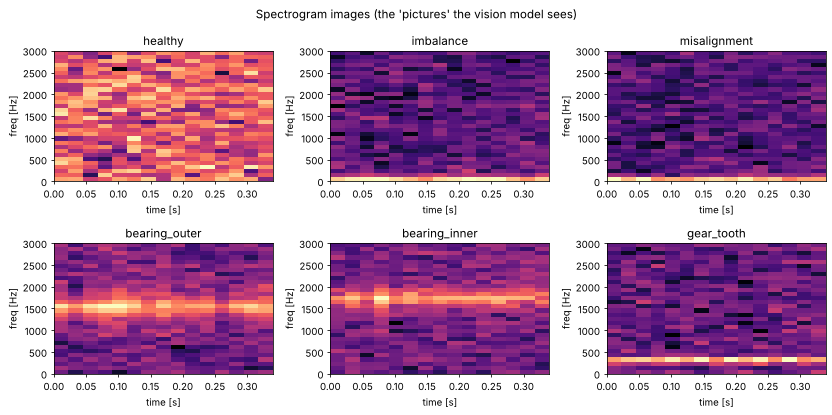

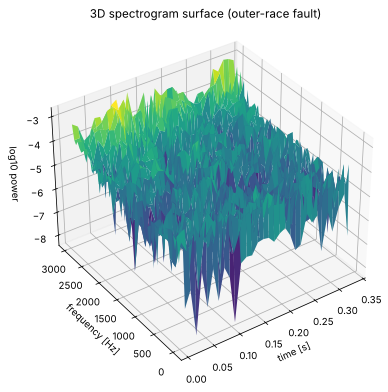

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, f in zip(axes.ravel(), dg.FAULTS):
    ax.imshow(img[idx[f]], origin="lower", aspect="auto", cmap="magma", extent=[0, 0.34, 0, 3000])
    ax.set_title(f)
    ax.set_xlabel("time [s]")
    ax.set_ylabel("freq [Hz]")
    ax.grid(False)
fig.suptitle("Spectrogram images (the 'pictures' the vision model sees)")
fig.tight_layout()
save(fig, "15_spectrogram_gallery.png")
plt.show()

i = idx["bearing_outer"]
L = np.log10(Sxx[i, :64, :] + 1e-10)
TT, FF = np.meshgrid(t_sp, f_sp[:64])
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(TT, FF, L, cmap="viridis", linewidth=0, antialiased=True)
ax.set_xlabel("time [s]")
ax.set_ylabel("frequency [Hz]")
ax.set_zlabel("log10 power")
ax.set_title("3D spectrogram surface (outer-race fault)")
ax.view_init(elev=35, azim=-125)
save(fig, "16_spectrogram_3d_surface.png")
plt.show()

In [ ]:
# Optional PyTorch models (UNVERIFIED code path; runs only when torch is installed).
from deep_torch import HAS_TORCH

if HAS_TORCH:
    import deep_torch as dt
    try:
        Xr = dt.prepare_raw(signals, 2)
        for nm, mdl, fac in (("1D-CNN (PyTorch)", dt.CNN1D(), 2), ("LSTM (PyTorch)", dt.LSTMClassifier(), 8)):
            Xr = dt.prepare_raw(signals, fac)
            a, f1m = dt.train_eval(mdl, Xr[tr], y.iloc[tr].to_numpy(), Xr[te], y.iloc[te].to_numpy(), epochs=8)
            rows.append(dict(model=nm, input="raw signal", accuracy=a, acc_std=np.nan, macro_f1=f1m,
                             evaluation="single hold-out by machine (20 %)", status="executed (torch present)"))
            print(nm, round(a, 3), round(f1m, 3))
    except Exception as e:
        print("torch path failed:", repr(e))
else:
    print("torch not installed -> PyTorch CNN/LSTM were NOT run")
if not any("PyTorch" in r["model"] for r in rows):
    for nm in ("1D-CNN (PyTorch)", "LSTM (PyTorch)"):
        rows.append(dict(model=nm, input="raw signal", accuracy=np.nan, acc_std=np.nan, macro_f1=np.nan,
                         evaluation="-", status="NOT RUN (torch unavailable when this was built)"))

torch not installed -> PyTorch CNN/LSTM were NOT run


## 10. Model comparison (honest table)
All models are scored on **unseen machines** from the **same simulator**. High scores therefore mean "the pipeline works on simulated data", not "it will work on your plant".

                      model                    input  accuracy  acc_std  macro_f1                      evaluation                                           status
0       Logistic regression   20 engineered features     0.980    0.008     0.980  5-fold GroupKFold (by machine)                                         executed
1             Random forest   20 engineered features     0.984    0.011     0.984  5-fold GroupKFold (by machine)                                         executed
2   Hist. gradient boosting   20 engineered features     0.983    0.014     0.983  5-fold GroupKFold (by machine)                                         executed
3       MLP on log-spectrum     128-bin log spectrum     0.709    0.025     0.708  5-fold GroupKFold (by machine)                                         executed
4  MLP on spectrogram image  32x15 spectrogram image     0.607    0.026     0.604  5-fold GroupKFold (by machine)                                         executed
5          1D-CNN (PyT

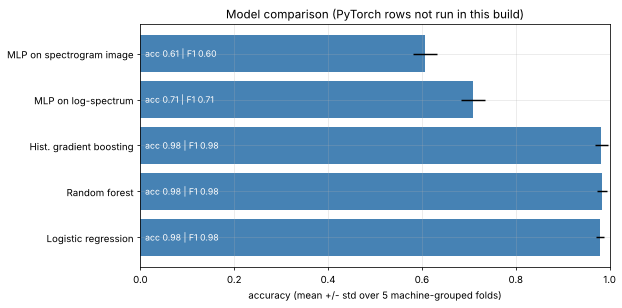

In [ ]:
comp = pd.DataFrame(rows)
comp.to_csv("model_comparison.csv", index=False)
display(comp.round(3))
ok = comp.dropna(subset=["accuracy"])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ok.model, ok.accuracy, xerr=ok.acc_std.fillna(0), color="steelblue")
for k, (a, f1m) in enumerate(zip(ok.accuracy, ok.macro_f1)):
    ax.text(0.01, k, f"acc {a:.2f} | F1 {f1m:.2f}", va="center", color="white", fontsize=9)
ax.set_xlim(0, 1.0)
ax.set_xlabel("accuracy (mean +/- std over 5 machine-grouped folds)")
ax.set_title("Model comparison (PyTorch rows not run in this build)")
fig.tight_layout()
save(fig, "17_model_comparison.png")
plt.show()

## 11. Time Series: health index, RUL with uncertainty
We simulate **25 run-to-failure machines** (5 per fault type; failure when severity reaches 1.0; 1 step = 1 day, an assumption). A **health index** (distance from the machine's own early-life baseline) is fitted with a power-law degradation curve; the RUL is the time until it crosses a failure threshold learned from 15 training machines. Test machines: 10 others.
The raw bootstrap interval is known to be too narrow, so we **calibrate** it with errors observed on the training machines (split-conformal style).

In [ ]:
FLEET_FAULTS = ["bearing_outer", "bearing_inner", "imbalance", "misalignment", "gear_tooth"]
fleet = []
t0 = time.time()
for i in range(25):
    f = FLEET_FAULTS[i % 5]
    T = int(np.random.default_rng(i).integers(90, 131))
    s, m = dg.run_to_failure(f, T, seed=100 + i, machine_id=i)
    F = ft.features_dataframe(s, m.speed_hz)
    fleet.append(dict(i=i, fault=f, T=T, meta=m, feat=F, hi=rul.health_index(F)))
print(f"simulated fleet in {time.time() - t0:.0f}s; life lengths:", [x["T"] for x in fleet][:10], "...")
thr = {f: float(np.median([x["hi"][-1] for x in fleet if x["i"] < 15 and x["fault"] == f])) for f in FLEET_FAULTS}
print("failure thresholds (health index):", {k: round(v, 2) for k, v in thr.items()})
FRACS = (0.5, 0.65, 0.8)


def predict_at(x, frac, n_boot=100):
    k = int(x["T"] * frac)
    return k, rul.rul_with_uncertainty(np.arange(k), x["hi"][:k], thr[x["fault"]], n_boot=n_boot, seed=x["i"])


cal_pred, cal_true = [], []
for x in fleet[:15]:
    for fr in FRACS:
        k, r = predict_at(x, fr, 30)
        cal_pred.append(r["median"])
        cal_true.append(x["T"] - k)
offsets = rul.calibrate_interval(cal_pred, cal_true)
cal_err = np.array(cal_true) - np.array(cal_pred)
print("calibration offsets (steps):", np.round(offsets, 1))

res = []
for x in fleet[15:]:
    for fr in FRACS:
        k, r = predict_at(x, fr)
        clo, chi = rul.apply_calibration(r["median"], offsets)
        res.append(dict(machine=x["i"], fault=x["fault"], frac=fr, true=x["T"] - k, pred=r["median"], raw_lo=r["lo"], raw_hi=r["hi"], cal_lo=clo, cal_hi=chi))
res = pd.DataFrame(res)
res["abs_err"] = (res.pred - res.true).abs()
print(f"test MAE: {res.abs_err.mean():.1f} steps | raw 90% interval coverage: {((res.raw_lo <= res.true) & (res.true <= res.raw_hi)).mean():.0%} "
      f"| calibrated coverage: {((res.cal_lo <= res.true) & (res.true <= res.cal_hi)).mean():.0%} (n = {len(res)} predictions only!)")
res.groupby("fault").abs_err.mean().round(1)

simulated fleet in 9s; life lengths: [124, 109, 124, 123, 119, 117, 108, 128, 119, 107] ...
failure thresholds (health index): {'bearing_outer': 6.26, 'bearing_inner': 5.92, 'imbalance': 3.97, 'misalignment': 3.55, 'gear_tooth': 1.34}
calibration offsets (steps): [-114.6   37.6]
test MAE: 29.3 steps | raw 90% interval coverage: 13% | calibrated coverage: 93% (n = 30 predictions only!)


fault
bearing_inner    21.6
bearing_outer    25.2
gear_tooth       71.0
imbalance        15.6
misalignment     12.8

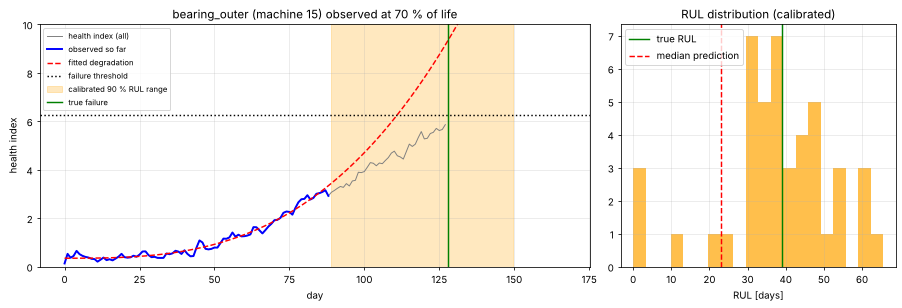

In [ ]:
x = fleet[15]
k, r = predict_at(x, 0.7)
tt = np.arange(x["T"] + 40)
clo, chi = rul.apply_calibration(r["median"], offsets)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(np.arange(x["T"]), x["hi"], color="gray", lw=1, label="health index (all)")
axes[0].plot(np.arange(k), x["hi"][:k], "b", lw=2, label="observed so far")
axes[0].plot(tt, rul.predict_curve(r["model"], tt), "r--", label="fitted degradation")
axes[0].axhline(thr[x["fault"]], color="k", ls=":", label="failure threshold")
axes[0].axvspan(k + clo, k + chi, color="orange", alpha=0.25, label="calibrated 90 % RUL range")
axes[0].axvline(x["T"], color="green", lw=1.5, label="true failure")
axes[0].set_ylim(0, thr[x["fault"]] * 1.6)
axes[0].set_xlabel("day")
axes[0].set_ylabel("health index")
axes[0].set_title(f"{x['fault']} (machine {x['i']}) observed at 70 % of life")
axes[0].legend(fontsize=8)
axes[1].hist(np.clip(r["median"] + cal_err, 0, None), bins=20, color="orange", alpha=0.7)
axes[1].axvline(x["T"] - k, color="green", label="true RUL")
axes[1].axvline(r["median"], color="r", ls="--", label="median prediction")
axes[1].set_xlabel("RUL [days]")
axes[1].set_title("RUL distribution (calibrated)")
axes[1].legend()
fig.tight_layout()
save(fig, "18_health_trend_rul.png")
plt.show()

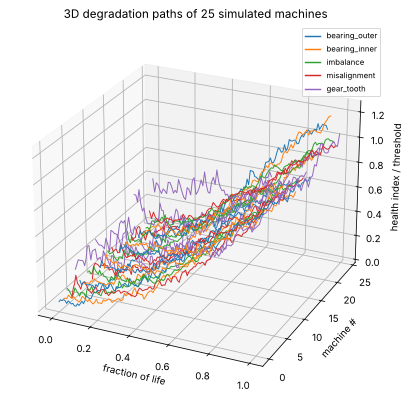

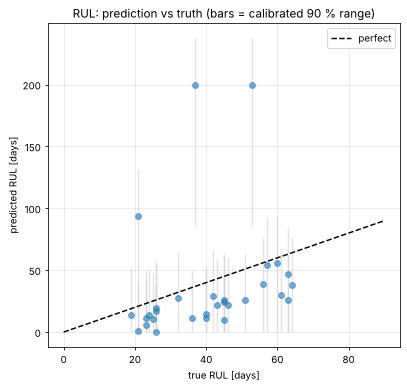

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
cols = dict(zip(FLEET_FAULTS, ["C0", "C1", "C2", "C3", "C4"]))
for x in fleet:
    life = np.arange(x["T"]) / x["T"]
    ax.plot(life, np.full(x["T"], x["i"]), x["hi"] / thr[x["fault"]], color=cols[x["fault"]], lw=1)
for f, c in cols.items():
    ax.plot([], [], color=c, label=f)
ax.set_xlabel("fraction of life")
ax.set_ylabel("machine #")
ax.set_zlabel("health index / threshold")
ax.set_title("3D degradation paths of 25 simulated machines")
ax.legend(fontsize=8)
ax.view_init(elev=25, azim=-65)
save(fig, "19_degradation_3d.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.errorbar(res.true, res.pred, yerr=[res.pred - res.cal_lo, res.cal_hi - res.pred], fmt="o", alpha=0.6, ecolor="lightgray")
ax.plot([0, 90], [0, 90], "k--", label="perfect")
ax.set_xlabel("true RUL [days]")
ax.set_ylabel("predicted RUL [days]")
ax.set_title("RUL: prediction vs truth (bars = calibrated 90 % range)")
ax.legend()
save(fig, "20_rul_pred_vs_true.png")
plt.show()

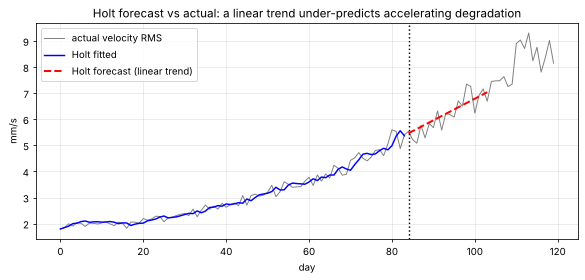

In [ ]:
# Time-series basics: Holt linear-trend smoothing forecast of velocity RMS (imbalance machine).
x = fleet[17]
v = x["feat"].vel_rms.to_numpy()
k = int(x["T"] * 0.7)
fit_h, fc = rul.holt_forecast(v[:k], alpha=0.4, beta=0.2, horizon=20)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(v, color="gray", lw=1, label="actual velocity RMS")
ax.plot(np.arange(k), fit_h, "b", lw=1.5, label="Holt fitted")
ax.plot(np.arange(k, k + 20), fc, "r--", lw=2, label="Holt forecast (linear trend)")
ax.axvline(k, color="k", ls=":")
ax.set_xlabel("day")
ax.set_ylabel("mm/s")
ax.set_title("Holt forecast vs actual: a linear trend under-predicts accelerating degradation")
ax.legend()
save(fig, "21_holt_forecast.png")
plt.show()

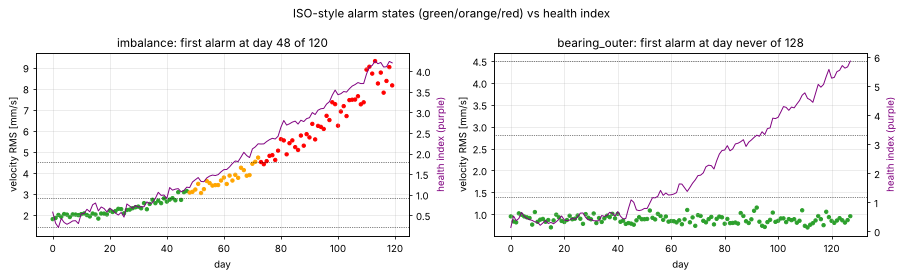

In [ ]:
# Alarm logic on two machines: imbalance (velocity works) vs outer-race bearing (velocity barely moves).
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, x in zip(axes, (fleet[17], fleet[15])):
    out = iso.AlarmLogic().run(x["feat"].vel_rms.to_numpy())
    colr = out.state.map({"NORMAL": "tab:green", "ALERT": "orange", "DANGER": "red"})
    ax.scatter(np.arange(len(out)), out.vel_rms, c=colr, s=12)
    for lim in iso.THRESHOLDS["medium_rigid"]:
        ax.axhline(lim, color="k", ls=":", lw=0.7)
    ax2 = ax.twinx()
    ax2.plot(x["hi"], color="purple", lw=1)
    ax2.set_ylabel("health index (purple)", color="purple")
    ax2.grid(False)
    first = out.index[out.state != "NORMAL"]
    ax.set_title(f"{x['fault']}: first alarm at day {first[0] if len(first) else 'never'} of {x['T']}")
    ax.set_xlabel("day")
    ax.set_ylabel("velocity RMS [mm/s]")
fig.suptitle("ISO-style alarm states (green/orange/red) vs health index")
fig.tight_layout()
save(fig, "22_alarm_states.png")
plt.show()

## 12. Maintenance plan and cost logic
Decision rule (also drawn in the README): zone D -> stop and inspect; else failure probability within the lead time >= 20 % -> urgent repair; else lower RUL bound within lead time + planning window -> plan next window; else monitor.
Predictive RUL distribution = median + errors seen on training machines. **All costs are illustrative assumptions (INR).**

In [ ]:
cp = mt.CostParams()
LEAD, WINDOW = 7, 14
plan = []
for x in fleet[15:]:
    k, r = predict_at(x, 0.7)
    samp = np.clip(r["median"] + cal_err, 0, None)
    rc = {"samples": samp, "lo": float(np.percentile(samp, 5)), "median": float(np.median(samp))}
    z = iso.zone(float(x["feat"].vel_rms.iloc[k - 1]))
    p_h = mt.failure_probability(samp, LEAD + WINDOW)
    ec = mt.expected_costs(p_h, rc["median"], cp)
    plan.append(dict(machine=x["i"], fault=x["fault"], true_rul=x["T"] - k, rul_median=round(rc["median"]), rul_p5=round(rc["lo"]), zone=z,
                     p_fail_21d=round(p_h, 2), action=mt.plan_action(z, rc, LEAD, WINDOW), repair_now_inr=round(ec["repair_now"]), wait_inr=round(ec["wait"])))
plan = pd.DataFrame(plan)
print(f"planned total {cp.planned_total:,.0f} INR vs unplanned total {cp.unplanned_total:,.0f} INR; break-even failure probability = {cp.planned_total / cp.unplanned_total:.2f}")
plan

planned total 83,000 INR vs unplanned total 538,000 INR; break-even failure probability = 0.15


   machine          fault  true_rul  rul_median  rul_p5 zone  p_fail_21d                action  repair_now_inr  wait_inr
0       15  bearing_outer        39          38       2    A        0.09      PLAN_NEXT_WINDOW          100566    123444
1       16  bearing_inner        34          27       0    A        0.29      PLAN_NEXT_WINDOW           95378    214444
2       17      imbalance        36          36       2    D        0.11  STOP_AND_INSPECT_NOW           99709    133556
3       18   misalignment        38          40       2    B        0.09      PLAN_NEXT_WINDOW          101549    123444
4       19     gear_tooth        35          32       1    A        0.13      PLAN_NEXT_WINDOW           97923    143667
5       20  bearing_outer        38          22       0    A        0.42      PLAN_NEXT_WINDOW           93281    275111
6       21  bearing_inner        31          22       0    A        0.42      PLAN_NEXT_WINDOW           93294    275111
7       22      imbalance       

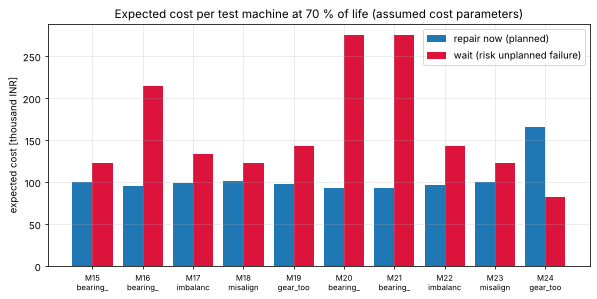

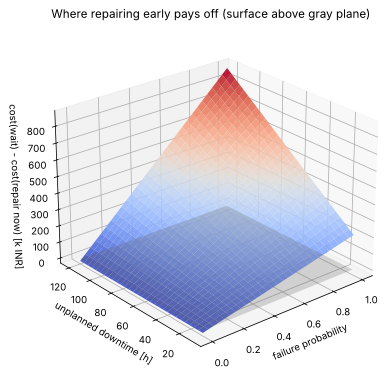

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xx = np.arange(len(plan))
ax.bar(xx - 0.2, plan.repair_now_inr / 1000, 0.4, label="repair now (planned)")
ax.bar(xx + 0.2, plan.wait_inr / 1000, 0.4, label="wait (risk unplanned failure)", color="crimson")
ax.set_xticks(xx)
ax.set_xticklabels([f"M{m}\n{f[:8]}" for m, f in zip(plan.machine, plan.fault)], fontsize=8)
ax.set_ylabel("expected cost [thousand INR]")
ax.set_title("Expected cost per test machine at 70 % of life (assumed cost parameters)")
ax.legend()
save(fig, "23_cost_comparison.png")
plt.show()

P, H = np.meshgrid(np.linspace(0, 1, 30), np.linspace(10, 120, 30))
dz = np.zeros_like(P)
for a in range(P.shape[0]):
    for b in range(P.shape[1]):
        c2 = mt.CostParams(unplanned_downtime_h=H[a, b])
        e = mt.expected_costs(P[a, b], 30, c2)
        dz[a, b] = (e["wait"] - e["repair_now"]) / 1000
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(P, H, dz, cmap="coolwarm", alpha=0.9)
ax.plot_surface(P, H, np.zeros_like(dz), color="gray", alpha=0.25)
ax.set_xlabel("failure probability")
ax.set_ylabel("unplanned downtime [h]")
ax.set_zlabel("cost(wait) - cost(repair now) [k INR]")
ax.set_title("Where repairing early pays off (surface above gray plane)")
ax.view_init(elev=25, azim=-130)
save(fig, "24_cost_3d_surface.png")
plt.show()

## 13. Reinforcement Learning / Game AI: keep running or repair?
A tiny MDP: a machine wears through states 0 (new) ... 4 (very worn), 5 (failed). Each step the agent either *runs* (earns revenue, may wear) or *repairs* (costs money, resets). A failure is expensive. We train **Q-learning** and cross-check against exact **value iteration** and two simple rule-based policies.

In [ ]:
Q, ep_returns = mt.q_learning(episodes=3000, seed=0)
Qv = mt.value_iteration()
policies = {"run to failure": [0] * 6, "repair at state >= 3": [0, 0, 0, 1, 1, 1], "Q-learning": Q.argmax(1), "value iteration (exact)": Qv.argmax(1)}
pol_rows = []
for nm, pol in policies.items():
    r_, f_ = mt.evaluate_policy(pol)
    pol_rows.append(dict(policy=nm, actions_by_state=list(map(int, pol)), reward_per_step=round(r_, 2), failures_per_100_steps=round(f_, 2)))
pol_df = pd.DataFrame(pol_rows)
print("actions: 0 = run, 1 = repair (state 5 = failed, repair is forced)")
pol_df

actions: 0 = run, 1 = repair (state 5 = failed, repair is forced)


                    policy    actions_by_state  reward_per_step  failures_per_100_steps
0           run to failure  [0, 0, 0, 0, 0, 0]            80.13                    2.17
1     repair at state >= 3  [0, 0, 0, 1, 1, 1]            90.35                    0.00
2               Q-learning  [0, 0, 1, 1, 0, 0]            91.88                    0.00
3  value iteration (exact)  [0, 0, 1, 1, 1, 0]            91.88                    0.00

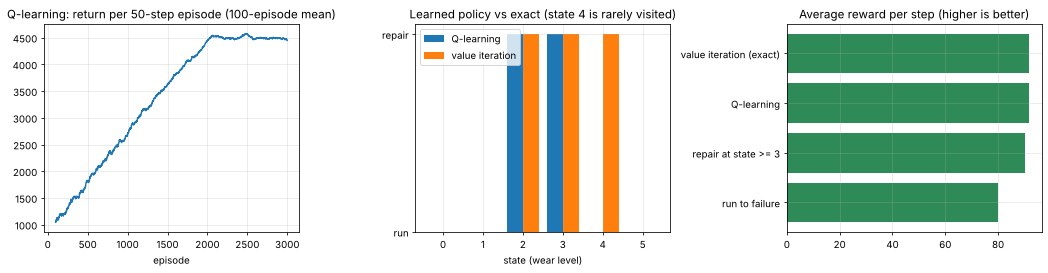

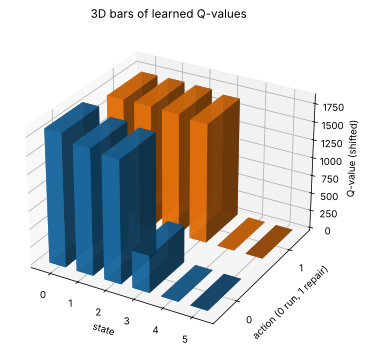

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sm = pd.Series(ep_returns).rolling(100).mean()
axes[0].plot(sm)
axes[0].set_title("Q-learning: return per 50-step episode (100-episode mean)")
axes[0].set_xlabel("episode")
axes[1].bar(np.arange(6) - 0.2, Q.argmax(1), 0.4, label="Q-learning")
axes[1].bar(np.arange(6) + 0.2, Qv.argmax(1), 0.4, label="value iteration")
axes[1].set_xlabel("state (wear level)")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["run", "repair"])
axes[1].set_title("Learned policy vs exact (state 4 is rarely visited)")
axes[1].legend()
axes[2].barh(pol_df.policy, pol_df.reward_per_step, color="seagreen")
axes[2].set_title("Average reward per step (higher is better)")
fig.tight_layout()
save(fig, "25_rl_learning_and_policy.png")
plt.show()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
xs, ys = np.meshgrid(np.arange(6), np.arange(2))
ax.bar3d(xs.ravel() - 0.3, ys.ravel() - 0.3, np.zeros(12), 0.6, 0.6, Q.T.ravel() - Q.min(), color=np.where(ys.ravel() == 0, "tab:blue", "tab:orange"), alpha=0.85)
ax.set_xlabel("state")
ax.set_ylabel("action (0 run, 1 repair)")
ax.set_yticks([0, 1])
ax.set_zlabel("Q-value (shifted)")
ax.set_title("3D bars of learned Q-values")
ax.view_init(elev=28, azim=-60)
save(fig, "26_rl_q_values_3d.png")
plt.show()

## 14. Natural Language Processing: fault type from maintenance-log text
TF-IDF + logistic regression on synthetic log sentences (templates + abbreviations, typos, noise phrases, 4 % label noise). Because train and test come from the *same templates*, the accuracy is optimistic; real technician text is far messier.

NLP test accuracy 0.979, macro-F1 0.979
accuracy on the SQL-database logs: 1.000 (n = 36, same templates -> optimistic)
  bearing_inner bearing_outer  gear_tooth           healthy imbalance  misalignment
0         inner         outer       tooth            normal     rotor  misalignment
1    inner race    outer race        gear                no        1x     alignment
2    inner ring           brg        mesh           routine       fan      coupling
3          race       bearing     gearbox          greasing        at          cplg
4     race wear  high pitting  gear tooth  routine greasing  impeller         shaft


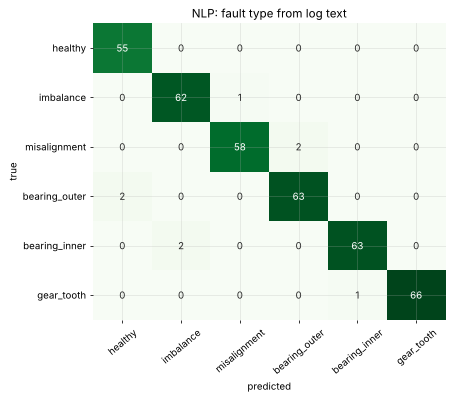

In [ ]:
from sklearn.model_selection import train_test_split

logs = textlogs.generate_logs(1500, seed=0)
Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(logs.text, logs.fault, test_size=0.25, stratify=logs.fault, random_state=SEED)
nlp = Pipeline([("tfidf", __import__("sklearn.feature_extraction.text", fromlist=["x"]).TfidfVectorizer(preprocessor=textlogs.clean_text, ngram_range=(1, 2), min_df=2)),
                ("clf", LogisticRegression(max_iter=2000))])
nlp.fit(Xtr_t, ytr_t)
pn = nlp.predict(Xte_t)
print(f"NLP test accuracy {accuracy_score(yte_t, pn):.3f}, macro-F1 {f1_score(yte_t, pn, average='macro'):.3f}")
dbl = pd.read_sql("SELECT log_text, fault_label FROM maintenance_logs", conn)
print(f"accuracy on the SQL-database logs: {accuracy_score(dbl.fault_label, nlp.predict(dbl.log_text)):.3f} (n = {len(dbl)}, same templates -> optimistic)")
vec, clf = nlp.named_steps["tfidf"], nlp.named_steps["clf"]
fn = np.array(vec.get_feature_names_out())
display(pd.DataFrame({c: fn[np.argsort(clf.coef_[i])[-5:][::-1]] for i, c in enumerate(clf.classes_)}))
cmn = confusion_matrix(yte_t, pn, labels=dg.FAULTS)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cmn, annot=True, fmt="d", cmap="Greens", xticklabels=dg.FAULTS, yticklabels=dg.FAULTS, cbar=False, ax=ax)
ax.set_title("NLP: fault type from log text")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.tick_params(axis="x", rotation=40)
save(fig, "27_nlp_confusion.png")
plt.show()

## 15. Geospatial Analysis: plant map, proximity and risk
No basemap or shapefiles (not available offline), so maps are plain longitude/latitude plots. Plants are fictional; city coordinates are approximate. Proximity analysis uses haversine distance to the nearest service hub (Ludhiana or Mohali, assumed) and an assumed 45 km/h road speed.

In [ ]:
plants = pd.read_sql("SELECT * FROM plants", conn)
rank["zone"] = rank.vel_rms.map(iso.zone)
risk = rank.groupby("plant_id").agg(n_machines=("machine_id", "count"), mean_vel=("vel_rms", "mean"), n_zone_CD=("zone", lambda z: int(z.isin(["C", "D"]).sum())))
plants = plants.merge(risk, on="plant_id")
plants["risk_share"] = plants.n_zone_CD / plants.n_machines


def haversine(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


hubs = plants[plants.city.isin(["Ludhiana", "Mohali"])]
dist = [min(haversine(r.lat, r.lon, h.lat, h.lon) for h in hubs.itertuples()) for r in plants.itertuples()]
plants["km_to_hub"] = np.round(dist, 0)
plants["travel_h"] = np.round(plants.km_to_hub / 45, 1)
plants[["city", "n_machines", "n_zone_CD", "risk_share", "mean_vel", "km_to_hub", "travel_h"]].round(2)

        city  n_machines  n_zone_CD  risk_share  mean_vel  km_to_hub  travel_h
0   Ludhiana           4          2        0.50      2.34        0.0       0.0
1  Jalandhar           4          2        0.50      2.86       54.0       1.2
2   Amritsar           4          0        0.00      1.23      124.0       2.8
3    Patiala           4          3        0.75      2.67       51.0       1.1
4   Bathinda           4          0        0.00      1.10      116.0       2.6
5     Mohali           4          3        0.75      2.81        0.0       0.0

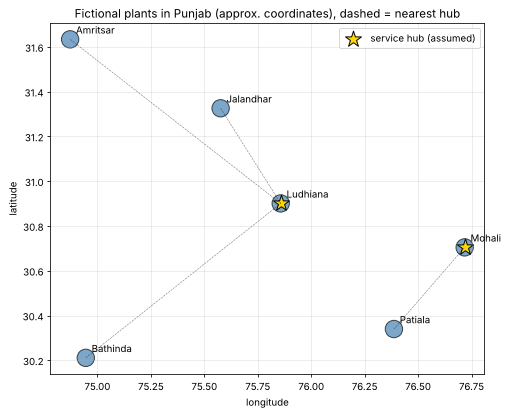

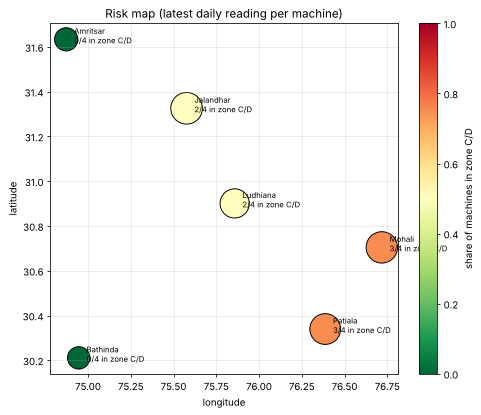

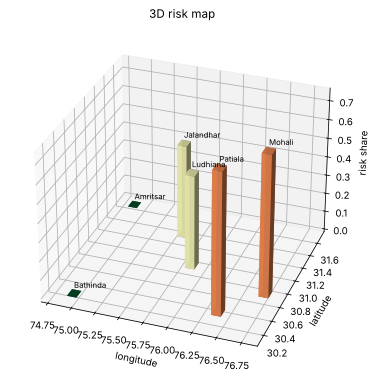

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(plants.lon, plants.lat, s=plants.n_machines * 80, c="steelblue", alpha=0.7, edgecolor="k")
for r in plants.itertuples():
    ax.annotate(r.city, (r.lon, r.lat), xytext=(6, 6), textcoords="offset points")
    h = min(hubs.itertuples(), key=lambda h: haversine(r.lat, r.lon, h.lat, h.lon))
    ax.plot([r.lon, h.lon], [r.lat, h.lat], "k--", lw=0.6, alpha=0.5)
ax.scatter(hubs.lon, hubs.lat, marker="*", s=300, c="gold", edgecolor="k", label="service hub (assumed)")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Fictional plants in Punjab (approx. coordinates), dashed = nearest hub")
ax.legend()
save(fig, "28_geo_plants_map.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(plants.lon, plants.lat, s=200 + plants.mean_vel * 300, c=plants.risk_share, cmap="RdYlGn_r", vmin=0, vmax=1, edgecolor="k")
for r in plants.itertuples():
    ax.annotate(f"{r.city}\n{r.n_zone_CD}/{r.n_machines} in zone C/D", (r.lon, r.lat), xytext=(8, -4), textcoords="offset points", fontsize=8)
fig.colorbar(sc, label="share of machines in zone C/D")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Risk map (latest daily reading per machine)")
save(fig, "29_geo_risk_map.png")
plt.show()

fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.bar3d(plants.lon - 0.05, plants.lat - 0.05, np.zeros(len(plants)), 0.1, 0.1, plants.risk_share, color=plt.cm.RdYlGn_r(plants.risk_share), alpha=0.9)
for r in plants.itertuples():
    ax.text(r.lon, r.lat, r.risk_share + 0.03, r.city, fontsize=8)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_zlabel("risk share")
ax.set_title("3D risk map")
ax.view_init(elev=30, azim=-70)
save(fig, "30_geo_risk_3d.png")
plt.show()

## 16. AI Ethics: slice evaluation, errors that matter, model card
We check whether accuracy differs across slices (load, speed, sensor gain) and which mistakes are costly: a **missed fault** (called healthy) is usually worse than a false alarm. See `MODEL_CARD.md` for intended use and limitations.

false-alarm rate (healthy -> fault): 1.7% | missed-fault rate (fault -> healthy): 1.6%


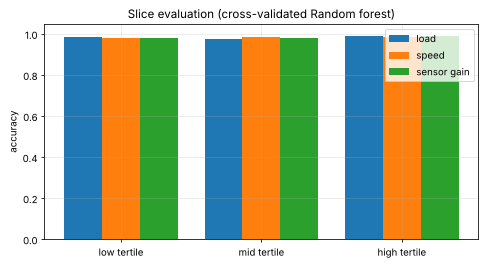

In [ ]:
sl = pd.DataFrame({"correct": (pred_s == y).to_numpy(), "load": pd.qcut(meta.load, 3, labels=["low", "mid", "high"]),
                   "speed": pd.qcut(meta.speed_hz, 3, labels=["low", "mid", "high"]), "sensor gain": pd.qcut(meta.gain, 3, labels=["low", "mid", "high"])})
fig, ax = plt.subplots(figsize=(8, 4))
for k, col in enumerate(["load", "speed", "sensor gain"]):
    a = sl.groupby(col, observed=True).correct.mean()
    ax.bar(np.arange(3) + 0.27 * (k - 1), a.values, 0.27, label=col)
ax.set_xticks(range(3))
ax.set_xticklabels(["low tertile", "mid tertile", "high tertile"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_title("Slice evaluation (cross-validated Random forest)")
ax.legend()
save(fig, "31_slice_evaluation.png")
plt.show()
healthy_called_fault = ((pred_s != 0) & (meta.fault == "healthy")).sum() / (meta.fault == "healthy").sum()
fault_called_healthy = ((pred_s == 0) & (meta.fault != "healthy")).sum() / (meta.fault != "healthy").sum()
print(f"false-alarm rate (healthy -> fault): {healthy_called_fault:.1%} | missed-fault rate (fault -> healthy): {fault_called_healthy:.1%}")

## 16b. Extended physics: speed ramps, several faults at once, slip, shocks
`physics_ext.py` adds effects the basic generator does not have (the basic generator and all earlier results stay unchanged):
- **run-up** (shaft speed ramps 15 -> 35 Hz): harmonics become diagonal order lines in the spectrogram
- **multi-fault**: e.g. outer-race bearing fault + imbalance in the same signal
- **slip**: random jitter of the bearing impacts (fraction of one period); more slip means a weaker envelope-spectrum peak
- **shock transients**: isolated hits that ring the resonance once (raise kurtosis without any periodic fault)
Still a simplified simulator, not validated on real machines.

kurtosis healthy 2.97 -> with 2 shocks 31.70


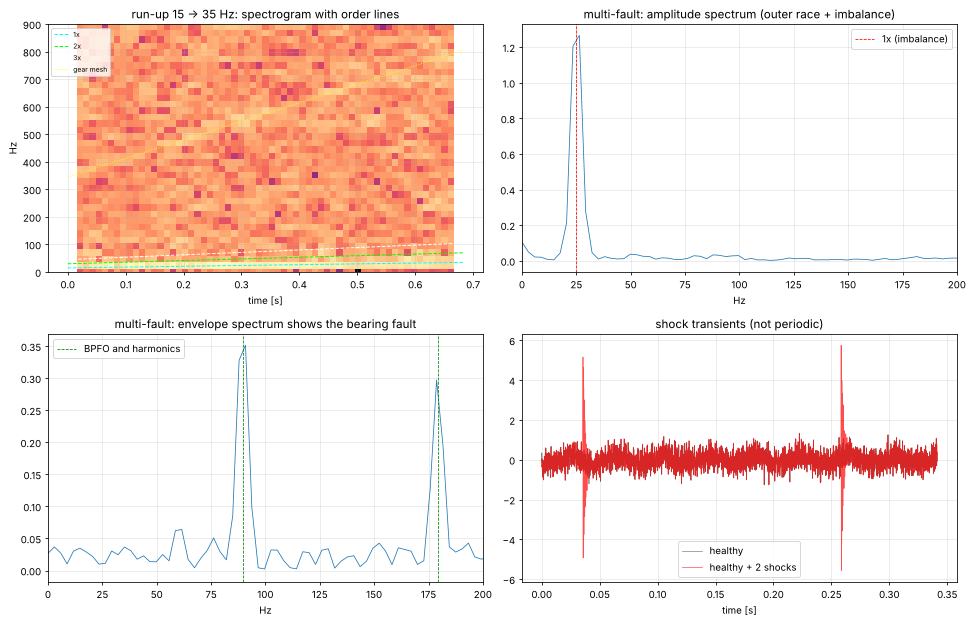

In [ ]:
import physics_ext as pe
from scipy.signal import spectrogram as _spec

geom = dg.BearingGeometry()
mpx = dg.MachineParams(0, 1.0, 3000.0, 0.3)
N_RAMP = 8192
ramp = pe.generate_signal_ext({"bearing_outer": 0.9}, 15.0, 0.7, np.random.default_rng(5), mp=mpx, speed_end=35.0, n=N_RAMP)
multi = pe.generate_signal_ext({"bearing_outer": 0.8, "imbalance": 0.8}, 25.0, 0.7, np.random.default_rng(6), mp=mpx)
shock = pe.generate_signal_ext({}, 25.0, 0.7, np.random.default_rng(7), mp=mpx, shock_amp=6.0, n_shocks=2)
quiet = pe.generate_signal_ext({}, 25.0, 0.7, np.random.default_rng(7), mp=mpx)
print(f"kurtosis healthy {ft.extract_features(quiet, speed_hz=25)['kurtosis']:.2f} -> with 2 shocks {ft.extract_features(shock, speed_hz=25)['kurtosis']:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
f_s, t_s, S = _spec(ramp, fs=dg.FS, nperseg=512, noverlap=384)
m = f_s <= 900
axes[0, 0].pcolormesh(t_s, f_s[m], 10 * np.log10(S[m] + 1e-12), shading="auto", cmap="magma")
tt_ = np.linspace(0, N_RAMP / dg.FS, 50)
f1x = 15.0 + 20.0 * tt_ / tt_[-1]
for k, c in ((1, "cyan"), (2, "lime"), (3, "white")):
    axes[0, 0].plot(tt_, k * f1x, c, ls="--", lw=1, label=f"{k}x")
axes[0, 0].plot(tt_, dg.N_TEETH * f1x, "yellow", ls=":", lw=1, label="gear mesh")
axes[0, 0].set_ylim(0, 900)
axes[0, 0].set_title("run-up 15 -> 35 Hz: spectrogram with order lines")
axes[0, 0].set_xlabel("time [s]")
axes[0, 0].set_ylabel("Hz")
axes[0, 0].legend(fontsize=7, loc="upper left")
fa, aa = ft.amplitude_spectrum(multi)
axes[0, 1].plot(fa, aa, lw=0.8)
axes[0, 1].set_xlim(0, 200)
axes[0, 1].axvline(25, color="r", ls="--", lw=0.8, label="1x (imbalance)")
axes[0, 1].set_title("multi-fault: amplitude spectrum (outer race + imbalance)")
axes[0, 1].set_xlabel("Hz")
axes[0, 1].legend()
fe_, ae_ = ft.envelope_spectrum(multi)
axes[1, 0].plot(fe_, ae_, lw=0.8)
axes[1, 0].set_xlim(0, 200)
for h_ in (1, 2, 3):
    axes[1, 0].axvline(h_ * geom.bpfo(25), color="g", ls="--", lw=0.8, label="BPFO and harmonics" if h_ == 1 else None)
axes[1, 0].set_title("multi-fault: envelope spectrum shows the bearing fault")
axes[1, 0].set_xlabel("Hz")
axes[1, 0].legend()
tm = np.arange(len(shock)) / dg.FS
axes[1, 1].plot(tm, quiet, color="gray", lw=0.7, label="healthy")
axes[1, 1].plot(tm, shock, "r", lw=0.7, alpha=0.7, label="healthy + 2 shocks")
axes[1, 1].set_title("shock transients (not periodic)")
axes[1, 1].set_xlabel("time [s]")
axes[1, 1].legend()
fig.tight_layout()
save(fig, "34_ext_physics_signals.png")
plt.show()

envelope SNR at severity 1.0: slip 0 -> 17.8, slip 0.25 -> 2.7


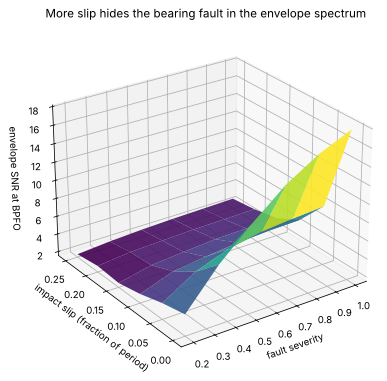

In [ ]:
# 3D: how severity and slip change the envelope-spectrum BPFO peak (mean of 4 random seeds per cell)
sevs, slips = np.linspace(0.2, 1.0, 6), np.linspace(0.0, 0.25, 6)
Z = np.zeros((len(slips), len(sevs)))
for a_, sl_ in enumerate(slips):
    for b_, sv_ in enumerate(sevs):
        Z[a_, b_] = np.mean([ft.extract_features(pe.generate_signal_ext({"bearing_outer": sv_}, 25.0, 0.7, np.random.default_rng(100 + k), slip=sl_, mp=mpx), speed_hz=25)["env_snr_bpfo"] for k in range(4)])
SV, SL = np.meshgrid(sevs, slips)
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(SV, SL, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("fault severity")
ax.set_ylabel("impact slip (fraction of period)")
ax.set_zlabel("envelope SNR at BPFO")
ax.set_title("More slip hides the bearing fault in the envelope spectrum")
ax.view_init(elev=26, azim=-125)
save(fig, "35_ext_slip_3d.png")
plt.show()
print(f"envelope SNR at severity 1.0: slip 0 -> {Z[0, -1]:.1f}, slip 0.25 -> {Z[-1, -1]:.1f}")

In [ ]:
# Multi-label classification: healthy + 5 single faults + 5 fault pairs (11 combinations), validated on unseen machines.
from sklearn.multiclass import OneVsRestClassifier

sx, mx = pe.generate_multifault_dataset(n_machines=20, per_combo=3, seed=11)
Xm = ft.features_dataframe(sx, mx.speed_hz.to_numpy())
ycols = [f"y_{f}" for f in pe.FAULT_NAMES]
Ym = mx[ycols].to_numpy()


def ovr():
    return Pipeline([("imp", SimpleImputer()), ("sc", StandardScaler()),
                     ("clf", OneVsRestClassifier(RandomForestClassifier(150, random_state=SEED, n_jobs=1)))])


predA = np.zeros_like(Ym)
predB = np.zeros_like(Ym)
for tr_i, te_i in GroupKFold(5).split(Xm, groups=mx.machine_id):
    predA[te_i] = ovr().fit(Xm.iloc[tr_i], Ym[tr_i]).predict(Xm.iloc[te_i])        # A: trained on all 11 combinations
    single = tr_i[mx.n_faults.to_numpy()[tr_i] <= 1]                                  # B: trained on healthy + single faults only
    predB[te_i] = ovr().fit(Xm.iloc[single], Ym[single]).predict(Xm.iloc[te_i])
pair = (mx.n_faults == 2).to_numpy()
exactA = (predA == Ym).all(1)
exactB = (predB == Ym).all(1)
rec = lambda P: [float(((P[pair, j] == 1) & (Ym[pair, j] == 1)).sum() / max(1, (Ym[pair, j] == 1).sum())) for j in range(5)]
print(f"A (trained with pairs):   exact-match on all rows {exactA.mean():.3f} | on pair rows {exactA[pair].mean():.3f}")
print(f"B (single faults only):   exact-match on pair rows {exactB[pair].mean():.3f}  <- generalisation to unseen combinations")
res_ml = pd.DataFrame({"label": pe.FAULT_NAMES, "F1 (A, all rows)": [f1_score(Ym[:, j], predA[:, j]) for j in range(5)],
                       "recall on pairs (A)": rec(predA), "recall on pairs (B)": rec(predB)}).round(3)
res_ml

A (trained with pairs):   exact-match on all rows 0.980 | on pair rows 0.970
B (single faults only):   exact-match on pair rows 0.520  <- generalisation to unseen combinations


           label  F1 (A, all rows)  recall on pairs (A)  recall on pairs (B)
0      imbalance             0.996                0.994                0.806
1   misalignment             1.000                1.000                0.558
2  bearing_outer             0.997                0.992                0.558
3  bearing_inner             0.961                0.900                0.600
4     gear_tooth             0.997                0.992                0.967

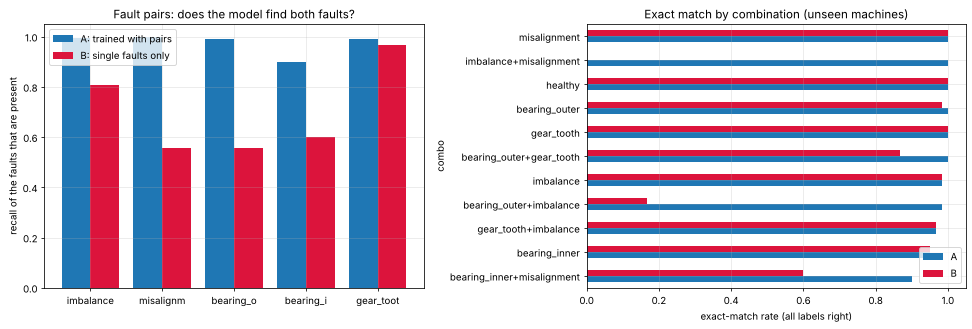

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
xx = np.arange(5)
axes[0].bar(xx - 0.2, res_ml["recall on pairs (A)"], 0.4, label="A: trained with pairs")
axes[0].bar(xx + 0.2, res_ml["recall on pairs (B)"], 0.4, label="B: single faults only", color="crimson")
axes[0].set_xticks(xx)
axes[0].set_xticklabels([f[:9] for f in pe.FAULT_NAMES])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("recall of the faults that are present")
axes[0].set_title("Fault pairs: does the model find both faults?")
axes[0].legend()
bc = pd.DataFrame({"combo": mx.combo, "A": exactA, "B": exactB}).groupby("combo").mean().sort_values("A")
bc.plot.barh(ax=axes[1], color=["tab:blue", "crimson"])
axes[1].set_xlabel("exact-match rate (all labels right)")
axes[1].set_title("Exact match by combination (unseen machines)")
fig.tight_layout()
save(fig, "36_ext_multifault_results.png")
plt.show()

## 16c. Advanced diagnostics: kurtogram and a healthy-only novelty detector
- **Kurtogram** (`advanced_diagnostics.py`): spectral kurtosis finds the frequency band where impacts are strongest, so the envelope band does not have to be fixed in advance.
- **Novelty detector**: fitted on *healthy* signals only (no fault labels). Threshold = 99 % quantile of out-of-fold healthy scores. Tested on machines it never saw.
- Honest note: on this simulator the fixed 1800-5000 Hz band already works almost perfectly, because every machine resonates at 2500-3500 Hz. The kurtogram is not better here; it matters when the resonance is unknown.

           fault  auc_fixed_band  auc_kurtogram_band    n
0  bearing_outer           0.999               0.987  461
1  bearing_inner           0.999               0.992  453


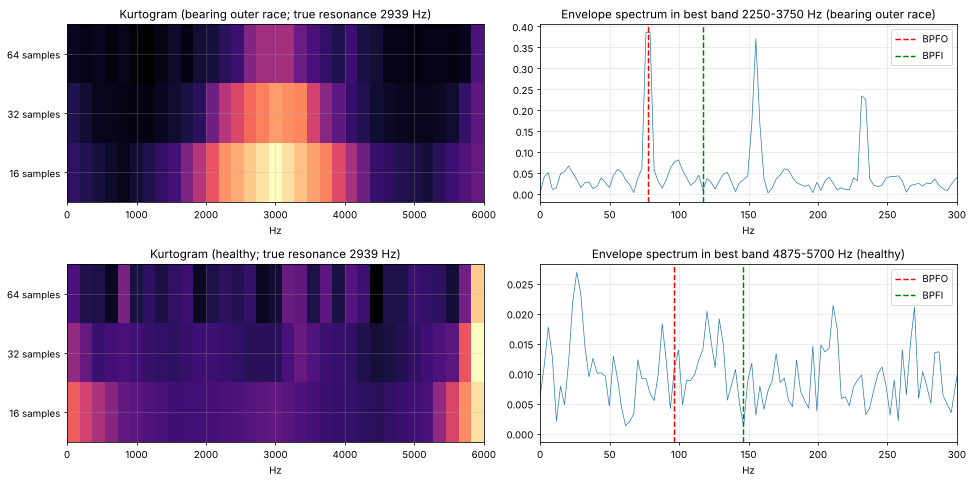

In [ ]:
import advanced_diagnostics as ad
from sklearn.metrics import roc_auc_score

geo = dg.BearingGeometry()
i_out = int(meta.index[(meta.fault == "bearing_outer") & (meta.severity > 0.7)][0])
i_hea = int(meta.index[meta.fault == "healthy"][0])
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for r, (idx, title) in enumerate(((i_out, "bearing outer race"), (i_hea, "healthy"))):
    f_k, K = ad.kurtogram(signals[idx])
    axes[r, 0].imshow(K, aspect="auto", origin="lower", extent=[f_k[0], f_k[-1], 0, len(ad.DEFAULT_NPERSEG)], cmap="magma")
    axes[r, 0].set_yticks(np.arange(len(ad.DEFAULT_NPERSEG)) + 0.5)
    axes[r, 0].set_yticklabels([f"{n} samples" for n in ad.DEFAULT_NPERSEG])
    axes[r, 0].set_title(f"Kurtogram ({title}; true resonance {meta.f_res[idx]:.0f} Hz)")
    axes[r, 0].set_xlabel("Hz")
    lo, hi, sk = ad.best_band(signals[idx])
    fe, E = ad.envelope_spectrum_band(signals[idx], (lo, hi))
    axes[r, 1].plot(fe, E, lw=0.7)
    axes[r, 1].set_xlim(0, 300)
    sp = meta.speed_hz[idx]
    axes[r, 1].axvline(geo.bpfo(sp), color="r", ls="--", label="BPFO")
    axes[r, 1].axvline(geo.bpfi(sp), color="g", ls="--", label="BPFI")
    axes[r, 1].legend()
    axes[r, 1].set_title(f"Envelope spectrum in best band {lo:.0f}-{hi:.0f} Hz ({title})")
    axes[r, 1].set_xlabel("Hz")
fig.tight_layout()
save(fig, "37_kurtogram_best_band.png")
plt.show()

rows = []
for fault, key in (("bearing_outer", "bpfo"), ("bearing_inner", "bpfi")):
    ids = meta.index[(meta.fault == "healthy") | ((meta.fault == fault) & (meta.severity >= 0.2))]
    y = (meta.fault[ids] == fault).astype(int).to_numpy()
    kur = [ad.band_envelope_snr(signals[i], meta.speed_hz[i])[0][key] for i in ids]
    fix = [ft.extract_features(signals[i], speed_hz=meta.speed_hz[i])["env_snr_" + key] for i in ids]
    rows.append(dict(fault=fault, auc_fixed_band=roc_auc_score(y, fix), auc_kurtogram_band=roc_auc_score(y, kur), n=len(ids)))
display(pd.DataFrame(rows).round(3))

flag rate per class on UNSEEN machines (healthy = false-alarm rate):
fault
healthy          0.025
imbalance        1.000
misalignment     1.000
bearing_outer    0.967
bearing_inner    0.933
gear_tooth       0.983

flag rate by severity (faulty classes):
sev_bin
(0.14, 0.4]    0.925
(0.4, 0.7]     1.000
(0.7, 1.01]    1.000


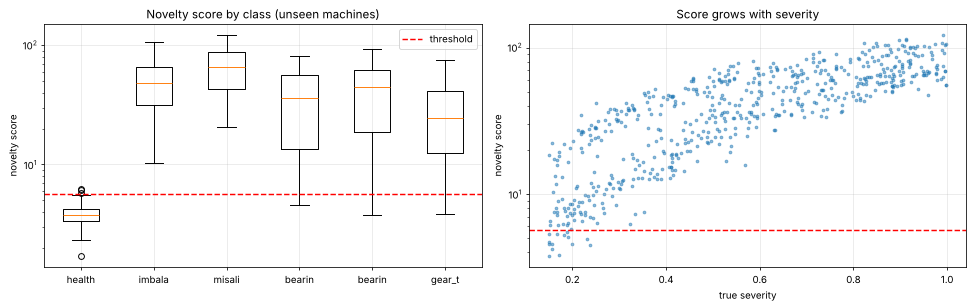

In [ ]:
Xf = ft.features_dataframe(signals, meta.speed_hz.to_numpy())
train_m = meta.machine_id < 15
hmask = train_m & (meta.fault == "healthy")
det = ad.HealthyNovelty().fit(Xf[hmask], groups=meta.machine_id[hmask])
test = ~train_m
sc = det.score(Xf[test])
mt_ = meta[test].assign(score=sc, flagged=sc > det.threshold_)
rate = mt_.groupby("fault").flagged.mean().reindex(dg.FAULTS)
print("flag rate per class on UNSEEN machines (healthy = false-alarm rate):")
print(rate.round(3).to_string())
faulty = mt_[mt_.fault != "healthy"].copy()
faulty["sev_bin"] = pd.cut(faulty.severity, [0.14, 0.4, 0.7, 1.01])
print("\nflag rate by severity (faulty classes):")
print(faulty.groupby("sev_bin").flagged.mean().round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot([mt_.score[mt_.fault == f] for f in dg.FAULTS])
axes[0].set_xticklabels([f[:6] for f in dg.FAULTS])
axes[0].axhline(det.threshold_, color="r", ls="--", label="threshold")
axes[0].set_yscale("log")
axes[0].set_ylabel("novelty score")
axes[0].legend()
axes[0].set_title("Novelty score by class (unseen machines)")
axes[1].scatter(faulty.severity, faulty.score, s=8, alpha=0.5)
axes[1].axhline(det.threshold_, color="r", ls="--")
axes[1].set_yscale("log")
axes[1].set_xlabel("true severity")
axes[1].set_ylabel("novelty score")
axes[1].set_title("Score grows with severity")
fig.tight_layout()
save(fig, "38_novelty_detector.png")
plt.show()

### 16c-2. Does the kurtogram help when the resonance is unknown?
Same outer-race detection task, but the machines' structural resonance is moved: inside the fixed 1800-5000 Hz band (2500-3500), below it (1000-1700) and above it (5000-5600).

  resonance_hz  auc_fixed_band  auc_kurtogram    n
0    2500-3500           1.000          0.996  240
1    1000-1700           0.850          0.985  240
2    5000-5600           0.809          0.999  240


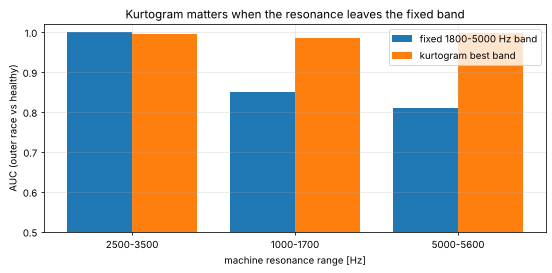

In [ ]:
shift = pd.DataFrame(ad.resonance_shift_experiment())
display(shift.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(shift))
ax.bar(xx - 0.2, shift.auc_fixed_band, 0.4, label="fixed 1800-5000 Hz band")
ax.bar(xx + 0.2, shift.auc_kurtogram, 0.4, label="kurtogram best band")
ax.set_xticks(xx)
ax.set_xticklabels(shift.resonance_hz)
ax.set_xlabel("machine resonance range [Hz]")
ax.set_ylabel("AUC (outer race vs healthy)")
ax.set_ylim(0.5, 1.02)
ax.legend()
ax.set_title("Kurtogram matters when the resonance leaves the fixed band")
fig.tight_layout()
save(fig, "39_kurtogram_resonance_shift.png")
plt.show()

## 16d. Order tracking and cepstrum (changing speed)
- **Order analysis** (`order_analysis.py`): resample at equal shaft-angle steps using the tachometer angle (assumed known; taken from the simulator), so shaft-related lines stay at a fixed order during a run-up.
- **Order tracking**: amplitude of chosen orders over time while the speed ramps.
- **Cepstrum**: shaft-speed spaced sidebands around the gear-mesh frequency form one peak at quefrency 1/speed.

       ramp  auc_frequency_domain  auc_order_domain    n
0  25-25 Hz                 1.000               1.0  160
1  20-30 Hz                 0.998               1.0  160
2  15-35 Hz                 0.984               1.0  160


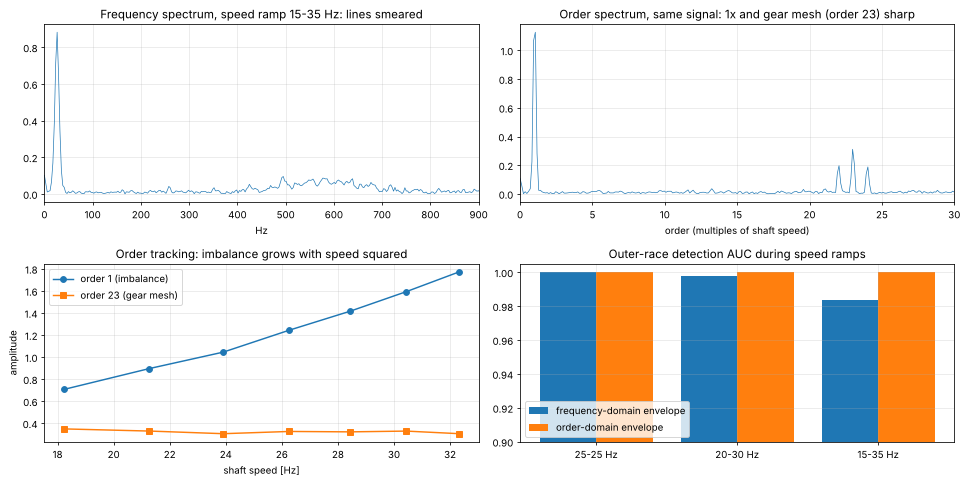

In [ ]:
import order_analysis as oa
import physics_ext as pe

mp_ = dg.MachineParams(0, 1.0, 3000.0, 0.3)
S0, S1 = 15.0, 35.0
x_g = pe.generate_signal_ext({"gear_tooth": 0.8, "imbalance": 0.6}, S0, 0.7, np.random.default_rng(1), mp=mp_, speed_end=S1)
_, fr_, th_ = pe.shaft_phase(len(x_g), dg.FS, S0, S1)
f_, a_ = ft.amplitude_spectrum(x_g)
o_, A_ = oa.order_spectrum(x_g, th_)
tr_ = oa.order_track(x_g, th_, orders=(1, dg.N_TEETH))
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes[0, 0].plot(f_, a_, lw=0.7)
axes[0, 0].set_xlim(0, 900)
axes[0, 0].set_xlabel("Hz")
axes[0, 0].set_title(f"Frequency spectrum, speed ramp {S0:g}-{S1:g} Hz: lines smeared")
axes[0, 1].plot(o_, A_, lw=0.7)
axes[0, 1].set_xlim(0, 30)
axes[0, 1].set_xlabel("order (multiples of shaft speed)")
axes[0, 1].set_title("Order spectrum, same signal: 1x and gear mesh (order 23) sharp")
axes[1, 0].plot(tr_["speed_hz"], tr_["amp"][1], "o-", label="order 1 (imbalance)")
axes[1, 0].plot(tr_["speed_hz"], tr_["amp"][dg.N_TEETH], "s-", label="order 23 (gear mesh)")
axes[1, 0].set_xlabel("shaft speed [Hz]")
axes[1, 0].set_ylabel("amplitude")
axes[1, 0].legend()
axes[1, 0].set_title("Order tracking: imbalance grows with speed squared")
ramp = pd.DataFrame(oa.ramp_experiment())
display(ramp.round(3))
xx = np.arange(len(ramp))
axes[1, 1].bar(xx - 0.2, ramp.auc_frequency_domain, 0.4, label="frequency-domain envelope")
axes[1, 1].bar(xx + 0.2, ramp.auc_order_domain, 0.4, label="order-domain envelope")
axes[1, 1].set_xticks(xx)
axes[1, 1].set_xticklabels(ramp.ramp)
axes[1, 1].set_ylim(0.9, 1.005)
axes[1, 1].legend(loc="lower left")
axes[1, 1].set_title("Outer-race detection AUC during speed ramps")
fig.tight_layout()
save(fig, "40_order_tracking.png")
plt.show()

{'auc_cepstrum': 0.666, 'auc_cepstrum_mesh_band': 0.867, 'auc_sideband_ratio': 0.695, 'auc_cepstrum_weak': 0.68, 'auc_sideband_weak': 0.3, 'n': 240}


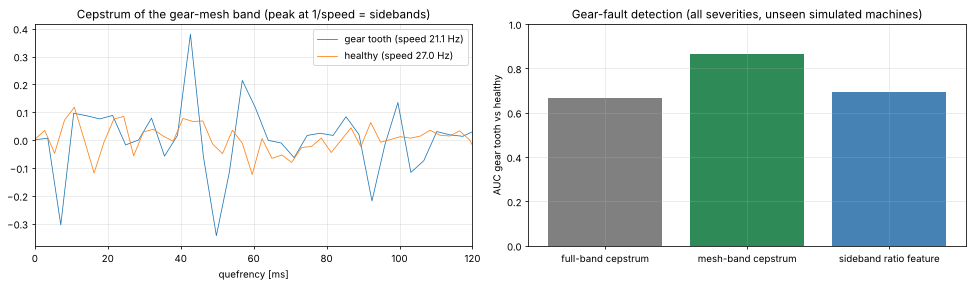

In [ ]:
ce = oa.cepstrum_experiment()
print({k: round(v, 3) if isinstance(v, float) else v for k, v in ce.items()})
i_g = int(meta.index[(meta.fault == "gear_tooth") & (meta.severity > 0.7)][0])
i_h = int(meta.index[meta.fault == "healthy"][0])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for idx, lab in ((i_g, "gear tooth"), (i_h, "healthy")):
    sp_ = meta.speed_hz[idx]
    q_, c_ = oa.real_cepstrum(signals[idx], f_max=1.15 * dg.N_TEETH * sp_, f_min=0.85 * dg.N_TEETH * sp_)
    axes[0].plot(q_ * 1000, c_, lw=0.8, label=f"{lab} (speed {sp_:.1f} Hz)")
axes[0].set_xlim(0, 120)
axes[0].set_xlabel("quefrency [ms]")
axes[0].set_title("Cepstrum of the gear-mesh band (peak at 1/speed = sidebands)")
axes[0].legend()
names = ["full-band cepstrum", "mesh-band cepstrum", "sideband ratio feature"]
vals = [ce["auc_cepstrum"], ce["auc_cepstrum_mesh_band"], ce["auc_sideband_ratio"]]
axes[1].bar(names, vals, color=["gray", "seagreen", "steelblue"])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("AUC gear tooth vs healthy")
axes[1].set_title("Gear-fault detection (all severities, unseen simulated machines)")
fig.tight_layout()
save(fig, "41_cepstrum_gear.png")
plt.show()

## 17. Dashboard-style summary

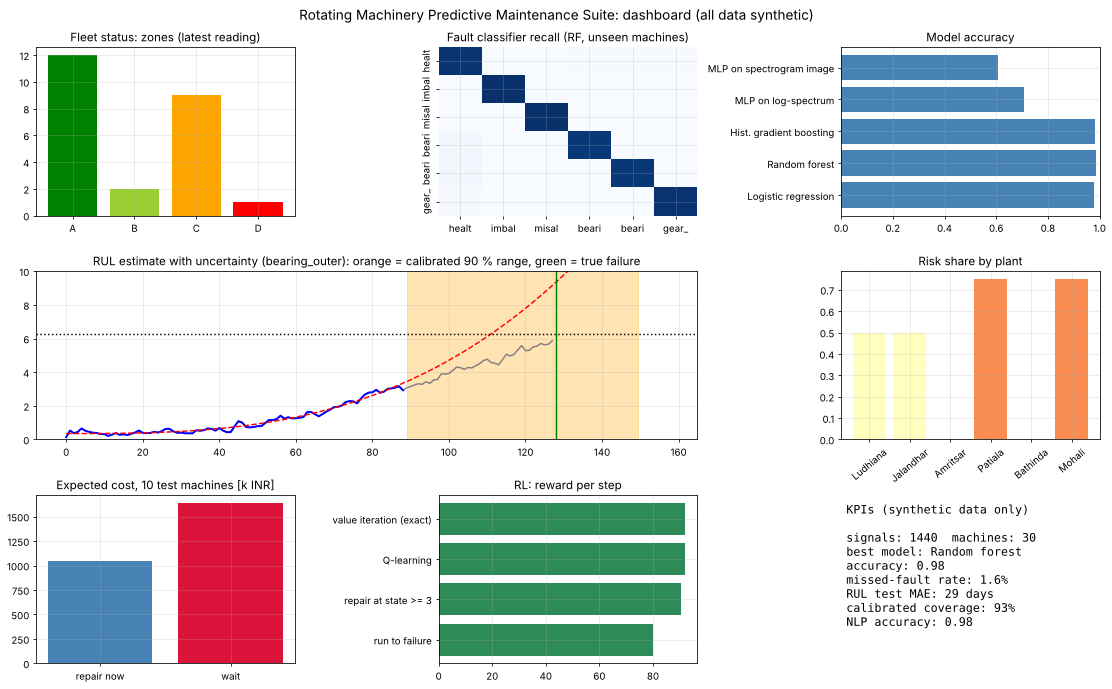

In [ ]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3)
a = fig.add_subplot(gs[0, 0])
zc = rank.zone.value_counts().reindex(list("ABCD"), fill_value=0)
a.bar(zc.index, zc.values, color=["green", "yellowgreen", "orange", "red"])
a.set_title("Fleet status: zones (latest reading)")
a = fig.add_subplot(gs[0, 1])
sns.heatmap(cm / cm.sum(1, keepdims=True), cmap="Blues", ax=a, cbar=False, xticklabels=[f[:5] for f in dg.FAULTS], yticklabels=[f[:5] for f in dg.FAULTS])
a.set_title("Fault classifier recall (RF, unseen machines)")
a = fig.add_subplot(gs[0, 2])
a.barh(ok.model, ok.accuracy, color="steelblue")
a.set_xlim(0, 1)
a.set_title("Model accuracy")
a = fig.add_subplot(gs[1, :2])
x = fleet[15]
k, r = predict_at(x, 0.7)
clo, chi = rul.apply_calibration(r["median"], offsets)
a.plot(x["hi"], color="gray")
a.plot(np.arange(k), x["hi"][:k], "b", lw=2)
a.plot(np.arange(x["T"] + 30), rul.predict_curve(r["model"], np.arange(x["T"] + 30)), "r--")
a.axhline(thr[x["fault"]], color="k", ls=":")
a.axvspan(k + clo, k + chi, color="orange", alpha=0.3)
a.axvline(x["T"], color="green")
a.set_ylim(0, thr[x["fault"]] * 1.6)
a.set_title(f"RUL estimate with uncertainty ({x['fault']}): orange = calibrated 90 % range, green = true failure")
a = fig.add_subplot(gs[1, 2])
a.bar(plants.city, plants.risk_share, color=plt.cm.RdYlGn_r(plants.risk_share))
a.tick_params(axis="x", rotation=40)
a.set_title("Risk share by plant")
a = fig.add_subplot(gs[2, 0])
a.bar(["repair now", "wait"], [plan.repair_now_inr.sum() / 1e3, plan.wait_inr.sum() / 1e3], color=["steelblue", "crimson"])
a.set_title("Expected cost, 10 test machines [k INR]")
a = fig.add_subplot(gs[2, 1])
a.barh(pol_df.policy, pol_df.reward_per_step, color="seagreen")
a.set_title("RL: reward per step")
a = fig.add_subplot(gs[2, 2])
a.axis("off")
kpi = (f"KPIs (synthetic data only)\n\nsignals: {len(signals)}  machines: 30\nbest model: {ok.sort_values('accuracy').iloc[-1].model}\n"
       f"accuracy: {ok.accuracy.max():.2f}\nmissed-fault rate: {fault_called_healthy:.1%}\nRUL test MAE: {res.abs_err.mean():.0f} days\n"
       f"calibrated coverage: {((res.cal_lo <= res.true) & (res.true <= res.cal_hi)).mean():.0%}\nNLP accuracy: {accuracy_score(yte_t, pn):.2f}")
a.text(0.02, 0.95, kpi, va="top", fontsize=12, family="monospace")
fig.suptitle("Rotating Machinery Predictive Maintenance Suite: dashboard (all data synthetic)", fontsize=14)
fig.tight_layout()
save(fig, "32_dashboard.png")
plt.show()

In [ ]:
print(f"{len(SAVED)} PNG charts saved:", *SAVED, sep="\n  ")
print(f"\ntotal runtime {time.time() - T_START:.0f}s")
print("\nNOT VERIFIED: PyTorch CNN/LSTM (torch missing), SHAP, pytest (own runner used), any real-world data, Jupyter kernel execution (custom runner used).")

41 PNG charts saved:
  01_signals_by_fault.png
  02_spectra_by_fault.png
  03_envelope_spectrum.png
  04_waterfall_3d.png
  05_sql_window_trends.png
  33_pandas_merge_pivot_resample_rolling.png
  06_cleaning_before_after.png
  07_feature_correlation.png
  08_features_3d_scatter.png
  09_iso_zones.png
  10_tree_depth_curve.png
  11_confusion_matrix_rf.png
  12_accuracy_by_severity.png
  13_noise_robustness.png
  14_permutation_importance.png
  15_spectrogram_gallery.png
  16_spectrogram_3d_surface.png
  17_model_comparison.png
  18_health_trend_rul.png
  19_degradation_3d.png
  20_rul_pred_vs_true.png
  21_holt_forecast.png
  22_alarm_states.png
  23_cost_comparison.png
  24_cost_3d_surface.png
  25_rl_learning_and_policy.png
  26_rl_q_values_3d.png
  27_nlp_confusion.png
  28_geo_plants_map.png
  29_geo_risk_map.png
  30_geo_risk_3d.png
  31_slice_evaluation.png
  34_ext_physics_signals.png
  35_ext_slip_3d.png
  36_ext_multifault_results.png
  37_kurtogram_best_band.png
  38_novelty_d